<a href="https://colab.research.google.com/github/Racsok/mineria/blob/desarrollo/analisis_dataset_FIFA_modelos_lineales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de dataset FIFA — Regularización con Ridge y Lasso
- Juan Pablo Mosquera
- David Zahid Riveros
- Oscar Manuel Contreras Gacha
- Anderson David Arenas Gutierrez

In [1]:
#%pip uninstall pandas-profiling
#%pip install --upgrade ydata-profiling setuptools

In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Scikit-Learn preprocessing & imputation
from sklearn.preprocessing import (
    MinMaxScaler, StandardScaler, RobustScaler,
    OneHotEncoder, MaxAbsScaler
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_validate

# Models & validation
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.svm import SVC

# Metrics
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, mean_absolute_error, r2_score
)

# Pandas config & RNG
pd.set_option("display.width", 110)
rng = np.random.default_rng(2026)
print("pandas", pd.__version__)

pandas 2.2.3


In [3]:
URL_DATASET = "https://raw.githubusercontent.com/Racsok/mineria/desarrollo/datasets/fifa_eda_stats.csv"

df = pd.read_csv(
    URL_DATASET,
    encoding="utf-8-sig",
    low_memory=False
)

print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

df.head()

Filas: 18207
Columnas: 57


,ID,Name,Age,Nationality,Overall,Potential,Club,Value,Wage,Preferred Foot,...,Composure,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause
0,158023,L. Messi,31,Argentina,94,94,FC Barcelona,€110.5M,€565K,Left,...,96.0,33.0,28.0,26.0,6.0,11.0,15.0,14.0,8.0,€226.5M
1,20801,Cristiano Ronaldo,33,Portugal,94,94,Juventus,€77M,€405K,Right,...,95.0,28.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0,€127.1M
2,190871,Neymar Jr,26,Brazil,92,93,Paris Saint-Germain,€118.5M,€290K,Right,...,94.0,27.0,24.0,33.0,9.0,9.0,15.0,15.0,11.0,€228.1M
3,193080,De Gea,27,Spain,91,93,Manchester United,€72M,€260K,Right,...,68.0,15.0,21.0,13.0,90.0,85.0,87.0,88.0,94.0,€138.6M
4,192985,K. De Bruyne,27,Belgium,91,92,Manchester City,€102M,€355K,Right,...,88.0,68.0,58.0,51.0,15.0,13.0,5.0,10.0,13.0,€196.4M


## Dataset
El dataset trabaja sobre estadisticas numericas del rendimiento de jugadores de futbol dentro del FIFA, cuenta con 57 columnas y la columna objetivo sobre la cual se analizan los datos es el valor monetario de un jugador en el mercado.

link dataset: https://github.com/Racsok/mineria/blob/desarrollo/datasets/fifa_eda_stats.csv
            https://www.kaggle.com/datasets/mukeshmanral/fifa-data-for-eda-and-stats

# Perfilado y limpieza

Las columnas Value, Wage y Release Clause vienen como strings con formato tipo "€110.5M", "€565K" o "€0". Esto impide cualquier operación estadística (correlación, media, escalado) porque pandas las trata como texto. La función convert_value_to_numeric:
Devuelve None si el valor es nulo o no es string (control defensivo).

* Elimina el símbolo € y espacios.
* Si contiene 'M', multiplica el número por 1 000 000 (millones).
* Si contiene 'K', multiplica por 1 000 (miles).
* Si es exactamente "0", devuelve 0.0.
* En cualquier otro caso intenta convertirlo a float; si falla, devuelve None.

In [4]:
"""Limpieza de valores de dinero"""
def convert_value_to_numeric(value_str):
    if pd.isna(value_str) or not isinstance(value_str, str):
        return None
    value_str = value_str.replace('€', '').strip()
    if 'M' in value_str:
        return float(value_str.replace('M', '')) * 1_000_000
    elif 'K' in value_str:
        return float(value_str.replace('K', '')) * 1_000
    elif value_str == '0':
        return 0.0
    else:
        try:
            return float(value_str)
        except ValueError:
            return None
df['Value'] = df['Value'].apply(convert_value_to_numeric)
df['Wage'] = df['Wage'].apply(convert_value_to_numeric)
df['Release Clause'] = df['Release Clause'].apply(convert_value_to_numeric)

In [5]:
print(df["Value"].value_counts(normalize=True).round(3))

Value
1100000.0     0.024
375000.0      0.020
425000.0      0.019
325000.0      0.019
450000.0      0.019
              ...  
63000000.0    0.000
51500000.0    0.000
53500000.0    0.000
58000000.0    0.000
81000000.0    0.000
Name: proportion, Length: 217, dtype: float64


## Perfilado

Se Ejecuta la función de perfilado que recorre todas las columnas del DataFrame y devuelve una tabla resumen con:

* tipo: el dtype de la columna (útil para detectar numéricas disfrazadas de texto).
* distintos: número de valores únicos (nunique), para medir cardinalidad.
* faltan_%: porcentaje de nulos (isna().mean() * 100), redondeado a 1 decimal.
* moda: el valor más frecuente (s.mode().iloc[0]), con control por si la columna está vacía.
* Para columnas numéricas, además: min, mediana, media y max.

Finalmente se hace set_index("columna") para que cada fila quede identificada por el nombre de la variable. Este perfil es clave porque expone de un vistazo tres problemas: la columna Loaned From con 93.1 % de nulos, Height y Weight guardadas como strings, y Release Clause con 8.6 % de faltantes.

In [6]:
def perfilar(df):
    filas = []
    for col in df.columns:
        s = df[col]
        fila = {
            "columna":   col,
            "tipo":      str(s.dtype),
            "distintos": s.nunique(),
            "faltan_%":  round(s.isna().mean() * 100, 1),
            "moda":      s.mode().iloc[0] if not s.mode().empty else None,
        }
        if pd.api.types.is_numeric_dtype(s):
            fila["min"]     = round(s.min(), 2)
            fila["mediana"] = round(s.median(), 2)
            fila["media"]   = round(s.mean(), 2)
            fila["max"]     = round(s.max(), 2)
        filas.append(fila)
    return pd.DataFrame(filas).set_index("columna")

perfilar(df)


,tipo,distintos,faltan_%,moda,min,mediana,media,max
columna,,,,,,,,
ID,int64,18207,0.0,16,16.0,221759.0,214298.34,246620.0
Name,object,17194,0.0,J. Rodríguez,NaN,NaN,NaN,NaN
Age,int64,29,0.0,21,16.0,25.0,25.12,45.0
Nationality,object,164,0.0,England,NaN,NaN,NaN,NaN
Overall,int64,48,0.0,66,46.0,66.0,66.24,94.0
Potential,int64,47,0.0,70,48.0,71.0,71.31,95.0
Club,object,651,1.3,AS Monaco,NaN,NaN,NaN,NaN
Value,float64,217,0.0,1100000.0,0.0,675000.0,2410695.89,118500000.0
Wage,float64,144,0.0,1000.0,0.0,3000.0,9731.31,565000.0


## Tres problemas encontrados y su solución

* **`Loaned From` con 93.1% de datos nulos:**  
  La gran mayoría de jugadores no están cedidos a préstamo, lo que genera una columna desierta de casi solo faltantes.  
  * **Solución:** Eliminar la columna por falta de varianza o convertirla en una bandera binaria `is_loaned` (1 si tiene club de origen, 0 si es `NaN`).

* **Valores numéricos guardados como texto (`Height` y `Weight`):**  
  Tienen formato de cadena tipo `6'0` y `165lbs`, lo que impide su análisis estadístico y cálculo de correlación directa.  
  * **Solución:** Aplicar una función de transformación en Pandas para convertir `Height` a centímetros y `Weight` a kilogramos (o libras numéricas) y castearlas a tipo `float64`.

* **Nulos masivos en cláusula de rescisión (`Release Clause` con 8.6% de faltantes):**  
  Existen 1,564 jugadores sin cláusula asignada en la base de datos.  
  * **Solución:** Imputar los faltantes calculando una estimación basada en la relación proporcional entre `Value` y `Overall`, o asignar 0 si el contrato no contempla dicha cláusula.

---

## Columnas objetivo y su reparto

###Numerica Value
Al ser **`Value`** una variable continua económica (target de regresión), el método `value_counts(normalize=True)` se utiliza para observar la concentración del mercado o agrupar por rangos. Su reparto estadístico directo muestra:

* **Mínimo:** €0.0
* **Mediana:** €675,000.0
* **Media:** €2,410,695.89
* **Máximo:** €118,500,000.0

*(El reparto de `Value` presenta un marcado sesgo positivo a la derecha [right-skewed], donde más del 50% de los jugadores tiene un valor de mercado inferior a €675,000, mientras que una élite de superestrellas eleva la media a €2.4M y alcanza un pico de €118.5M).*

### Categorica position
Usaremos las variables carateristicas del jufador para oredecir que posicion e jugara



## Limpieza y arreglos

### Solución al Problema 1: Columna `Loaned From` con valores nulos

Se crea una nueva columna `is_loaned` que indica si el jugador está cedido (1) o no (0). Posteriormente, se elimina la columna original `Loaned From`.

In [7]:
# Crear la columna binaria 'is_loaned': 1 si el jugador está cedido (no es NaN en 'Loaned From'), 0 en caso contrario.
df['is_loaned'] = df['Loaned From'].notna().astype(int)

# Eliminar la columna original 'Loaned From' ya que la nueva columna captura la información relevante.
df = df.drop(columns=['Loaned From'])

# Mostrar las primeras filas del DataFrame con la nueva columna y la columna eliminada
display(df[['Name', 'Club', 'is_loaned']].head())

# Verificar el tipo de datos y la ausencia de la columna original
print(df[['is_loaned']].info())

,Name,Club,is_loaned
0,L. Messi,FC Barcelona,0
1,Cristiano Ronaldo,Juventus,0
2,Neymar Jr,Paris Saint-Germain,0
3,De Gea,Manchester United,0
4,K. De Bruyne,Manchester City,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18207 entries, 0 to 18206
Data columns (total 1 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   is_loaned  18207 non-null  int64
dtypes: int64(1)
memory usage: 142.4 KB
None


### Solución al Problema 2: Valores numéricos guardados como texto (`Height` y `Weight`)

Se convierten las columnas `Height` y `Weight` de formato texto a numérico. Para `Height`, se convierte de pies y pulgadas a centímetros. Para `Weight`, se elimina la unidad 'lbs' y se convierte a float.

In [8]:
# Función para convertir altura de pies'pulgadas a centímetros
def convert_height_to_cm(height_str):
    if pd.isna(height_str) or not isinstance(height_str, str):
        return None
    try:
        feet, inches = map(int, height_str.replace('"', '').split("'"))
        return (feet * 30.48) + (inches * 2.54)
    except ValueError:
        return None

# Función para convertir peso de 'Xlbs' a un valor numérico en libras
def convert_weight_to_lbs(weight_str):
    if pd.isna(weight_str) or not isinstance(weight_str, str):
        return None
    try:
        return float(weight_str.replace('lbs', ''))
    except ValueError:
        return None

# Aplicar las funciones de conversión a las columnas 'Height' y 'Weight'
df['Height_cm'] = df['Height'].apply(convert_height_to_cm)
df['Weight_lbs'] = df['Weight'].apply(convert_weight_to_lbs)

# Eliminar las columnas originales 'Height' y 'Weight' si ya no son necesarias
df = df.drop(columns=['Height', 'Weight'])

# Mostrar las primeras filas del DataFrame con las nuevas columnas y las columnas eliminadas
display(df[['Name', 'Height_cm', 'Weight_lbs']].head())

# Verificar el tipo de datos de las nuevas columnas
print(df[['Height_cm', 'Weight_lbs']].info())

,Name,Height_cm,Weight_lbs
0,L. Messi,170.18,159.0
1,Cristiano Ronaldo,187.96,183.0
2,Neymar Jr,175.26,150.0
3,De Gea,193.04,168.0
4,K. De Bruyne,180.34,154.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18207 entries, 0 to 18206
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Height_cm   18159 non-null  float64
 1   Weight_lbs  18159 non-null  float64
dtypes: float64(2)
memory usage: 284.6 KB
None


### Solución al Problema 3: Nulos en la columna `Release Clause`

Release Clause tenía 1 564 valores nulos (8.6 %). La decisión de negocio adoptada es que un nulo significa que el jugador no tiene cláusula de rescisión, lo cual es perfectamente válido en el mundo real. Por eso se imputa con 0 en lugar de con media o mediana: imputar con la media inventaría un contrato que no existe y distorsionaría la distribución; imputar con 0 preserva el significado real ("sin cláusula"). Se verifica con isnull().sum() que ya no queden nulos y con df.info() que el tipo siga siendo float64.

In [9]:
# Imputar los valores nulos en 'Release Clause' con 0
df['Release Clause'] = df['Release Clause'].fillna(0)

# Verificar el número de valores nulos después de la imputación
print(f"Valores nulos en 'Release Clause' después de la imputación: {df['Release Clause'].isnull().sum()}")

# Mostrar una descripción estadística de la columna 'Release Clause' para verificar los cambios
display(df[['Name', 'Club', 'Value', 'Release Clause']].head())

# Verificar el tipo de datos de la columna 'Release Clause'
print(df[['Release Clause']].info())

Valores nulos en 'Release Clause' después de la imputación: 0


,Name,Club,Value,Release Clause
0,L. Messi,FC Barcelona,110500000.0,226500000.0
1,Cristiano Ronaldo,Juventus,77000000.0,127100000.0
2,Neymar Jr,Paris Saint-Germain,118500000.0,228100000.0
3,De Gea,Manchester United,72000000.0,138600000.0
4,K. De Bruyne,Manchester City,102000000.0,196400000.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18207 entries, 0 to 18206
Data columns (total 1 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Release Clause  18207 non-null  float64
dtypes: float64(1)
memory usage: 142.4 KB
None


## Descripcion

In [10]:
df.describe()

,ID,Age,Overall,Potential,Value,Wage,International Reputation,Weak Foot,Skill Moves,Jersey Number,...,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause,is_loaned,Height_cm,Weight_lbs
count,18207.000000,18207.000000,18207.000000,18207.000000,1.820700e+04,18207.000000,18159.000000,18159.000000,18159.000000,18147.000000,...,18159.000000,18159.000000,18159.000000,18159.000000,18159.000000,18159.000000,1.820700e+04,18207.000000,18159.000000,18159.000000
mean,214298.338606,25.122206,66.238699,71.307299,2.410696e+06,9731.312133,1.113222,2.947299,2.361308,19.546096,...,45.661435,16.616223,16.391596,16.232061,16.388898,16.710887,4.191200e+06,0.069424,181.257584,165.979129
std,29965.244204,4.669943,6.908930,6.136496,5.594933e+06,21999.290406,0.394031,0.660456,0.756164,15.947765,...,21.289135,17.695349,16.906900,16.502864,17.034669,17.955119,1.070778e+07,0.254180,6.730145,15.593344
min,16.000000,16.000000,46.000000,48.000000,0.000000e+00,0.000000,1.000000,1.000000,1.000000,1.000000,...,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000e+00,0.000000,154.940000,110.000000
25%,200315.500000,21.000000,62.000000,67.000000,3.000000e+05,1000.000000,1.000000,3.000000,2.000000,8.000000,...,24.000000,8.000000,8.000000,8.000000,8.000000,8.000000,3.920000e+05,0.000000,175.260000,154.000000
50%,221759.000000,25.000000,66.000000,71.000000,6.750000e+05,3000.000000,1.000000,3.000000,2.000000,17.000000,...,52.000000,11.000000,11.000000,11.000000,11.000000,11.000000,1.000000e+06,0.000000,180.340000,165.000000
75%,236529.500000,28.000000,71.000000,75.000000,2.000000e+06,9000.000000,1.000000,3.000000,3.000000,26.000000,...,64.000000,14.000000,14.000000,14.000000,14.000000,14.000000,3.000000e+06,0.000000,185.420000,176.000000
max,246620.000000,45.000000,94.000000,95.000000,1.185000e+08,565000.000000,5.000000,5.000000,5.000000,99.000000,...,91.000000,90.000000,92.000000,91.000000,90.000000,94.000000,2.281000e+08,1.000000,205.740000,243.000000


## Imputación de los datos
Muchas columnas presentan exactamente la misma cantidad de nulos, por lo que se procede a mirar la cantidad de jugadores con nulos en todas estas variables, y borrarlos ya que no aportan ningun valor.

Los Nulos en variables como club, joined, y contract valid until, tienen sentido en el negocio ya que un jugador sin club no tiene contrato, y es valido, se reemplazan los nulos por sin club y no disponible, para los jugadores sin jersey se deja un -1

### "Height_cm", "Weight_lbs", "Crossing"


In [11]:
columnas_principales = [
    "Height_cm", "Weight_lbs", "Crossing"
]

columnas_disponibles = [
    columna for columna in columnas_principales
    if columna in df.columns
]

filas_vacias_principales = df[columnas_disponibles].isna().all(axis=1)
display(df.loc[filas_vacias_principales].head(10))

,ID,Name,Age,Nationality,Overall,Potential,Club,Value,Wage,Preferred Foot,...,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause,is_loaned,Height_cm,Weight_lbs
13236,177971,J. McNulty,33,Scotland,62,62,Rochdale,120000.0,1000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13237,195380,J. Barrera,29,Nicaragua,62,62,Boyacá Chicó FC,300000.0,1000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13238,139317,J. Stead,35,England,62,62,Notts County,140000.0,3000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13239,240437,A. Semprini,20,Italy,62,72,Brescia,425000.0,1000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13240,209462,R. Bingham,24,England,62,66,Hamilton Academical FC,400000.0,1000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13241,219702,K. Dankowski,21,Poland,62,72,Śląsk Wrocław,425000.0,1000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13242,225590,I. Colman,23,Argentina,62,70,Club Atlético Aldosivi,450000.0,2000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13243,233782,M. Feeney,19,England,62,78,Everton,600000.0,5000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13244,239158,R. Minor,30,Denmark,62,62,Hobro IK,230000.0,2000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13245,242998,Klauss,21,Brazil,62,69,HJK Helsinki,425000.0,1000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN


Se cuenta cuántas filas cumplen la condición anterior y se eliminan Después se resetea el índice para que no queden huecos en la numeración. Se imprimen el número de filas eliminadas (48) y el nuevo tamaño del DataFrame (18159 × 57) para dejar constancia de la pérdida de datos.

In [12]:
filas_eliminadas = filas_vacias_principales.sum()

df = df.loc[~filas_vacias_principales].copy()
df.reset_index(drop=True, inplace=True)

print("Jugadores eliminados:", filas_eliminadas)
print("Nuevo tamaño del DataFrame:", df.shape)

Jugadores eliminados: 48
Nuevo tamaño del DataFrame: (18159, 57)


### "Club", "Joined" y "Contract"

Ahora se imputan los nulos que sí tienen sentido de negocio:

* Club → "Sin club": un jugador sin equipo no tiene club asignado, y eso es un estado real (agentes libres).
* Jersey Number → -1: se usa un valor centinela negativo para distinguir "sin dorsal asignado" de un dorsal real (que siempre es positivo).
* Joined → "Fecha no disponible": los jugadores sin club tampoco tienen fecha de incorporación.
* Contract Valid Until → "No disponible": mismo razonamiento, no hay contrato si no hay club.

Se verifica imprimiendo el conteo de nulos en Club (debe ser 0) y value_counts() para ver la distribución del club más común.

In [13]:
df["Club"] = df["Club"].fillna("Sin club")
df["Jersey Number"] = df["Jersey Number"].fillna(-1)
df["Joined"] = df["Joined"].fillna("Fecha no disponible")
df["Contract Valid Until"] = df["Contract Valid Until"].fillna("No disponible")

print("Nulos en Club:", df["Club"].isna().sum())
print(df["Club"].value_counts().head())

Nulos en Club: 0
Club
Sin club             241
RC Celta              33
Borussia Dortmund     33
Valencia CF           33
AS Monaco             33
Name: count, dtype: int64


Filtramos el DataFrame para quedarse solo con los jugadores marcados como "Sin club" y muestra las columnas Name, Jersey Number, Joined y Contract Valid Until con display. El objetivo es verificar la coherencia de la imputación anterior: si un jugador no tiene club, esperamos que también tenga Jersey Number = -1, Joined = "Fecha no disponible" y Contract Valid Until = "No disponible". Es una verificación de consistencia lógica del bloque anterior.

In [14]:
jugadores_sin_club = df[df["Club"] == "Sin club"]

display(
    jugadores_sin_club[
        ["Name", "Jersey Number", "Joined", "Contract Valid Until"]
    ].head(10)
)

,Name,Jersey Number,Joined,Contract Valid Until
452,L. Paredes,5.0,Fecha no disponible,No disponible
538,A. Granqvist,4.0,Fecha no disponible,No disponible
568,A. Lunev,12.0,Fecha no disponible,No disponible
677,I. Smolnikov,2.0,Fecha no disponible,No disponible
874,A. Dzyuba,22.0,Fecha no disponible,No disponible
953,Luís Neto,4.0,Fecha no disponible,No disponible
997,D. Kuzyaev,7.0,Fecha no disponible,No disponible
1008,G. Sio,21.0,Fecha no disponible,No disponible
1120,J. Villar,1.0,Fecha no disponible,No disponible
1271,C. Riveros,16.0,Fecha no disponible,No disponible


### Valores incoherentes en la columna body_type, los cuales no corresponden a un body type real.

Se cambian los valores inconsistentes por tipo de cuerpo "Normal" para mantener una coherencia en los datos

In [15]:
valores_anormales_body_type = ['Messi', 'C. Ronaldo', 'Neymar', 'Courtois', 'PLAYER_BODY_TYPE_25', 'Shaqiri', 'Akinfenwa']
df['Body Type'] = df['Body Type'].replace(valores_anormales_body_type, 'Normal')

# Verificar los cambios
print(df['Body Type'].value_counts())

Body Type
Normal    10602
Lean       6417
Stocky     1140
Name: count, dtype: int64


### Revison rapida de nullos

In [16]:
df.isnull().sum()
registros_nulos = df[df['Position'].isnull()]
print(registros_nulos)
df = df.dropna(subset=['Position'])

           ID             Name  Age Nationality  Overall  Potential      Club  Value  Wage Preferred Foot  \
5018   153160        R. Raldes   37     Bolivia       70         70  Sin club    0.0   0.0          Right   
6736   175393          J. Arce   33     Bolivia       68         68  Sin club    0.0   0.0           Left   
7922   195905     L. Gutiérrez   33     Bolivia       67         67  Sin club    0.0   0.0          Right   
9905   226044        R. Vargas   23     Bolivia       66         69  Sin club    0.0   0.0          Right   
10628  216751      D. Bejarano   26     Bolivia       65         66  Sin club    0.0   0.0          Right   
16402  193911          S. Paul   31       India       57         57  Sin club    0.0   0.0          Right   
16491  245167  L. Lalruatthara   23       India       57         63  Sin club    0.0   0.0           Left   
16745  228192       E. Lyngdoh   31       India       56         56  Sin club    0.0   0.0          Right   
17081  228198      

Se identificaron los registros con valores nulos en la variable objetivo **Position** y se procedió a eliminarlos del dataset. Esto se realizó debido a que contar con etiquetas completas en la variable objetivo es imprescindible para garantizar la calidad del entrenamiento y evaluación del modelo de clasificación.

---

### Mapeo de jugadores

In [17]:
print("Posiciones de Jugador Únicas:")
display(df['Position'].unique().tolist())

Posiciones de Jugador Únicas:


['RF',
 'ST',
 'LW',
 'GK',
 'RCM',
 'LF',
 'RS',
 'RCB',
 'LCM',
 'CB',
 'LDM',
 'CAM',
 'CDM',
 'LS',
 'LCB',
 'RM',
 'LAM',
 'LM',
 'LB',
 'RDM',
 'RW',
 'CM',
 'RB',
 'RAM',
 'CF',
 'RWB',
 'LWB']

Se procede a agrupar todas las posiciones en un solo cúmulo de posiciones coherente a la posición indicada para acotar porcentajes y simplificar el análisis

Distribución de Jugadores por Grupo de Posición:


,count
Position_Group,
Portero,2025
Defensas,3088
Laterales,2778
Medio centro defensivo,1439
Medio centro puro,4399
Medio centro ofensivo,1000
Extremos,751
Delanteros,2667



Distribución Porcentual por Grupo de Posición (%):


,count
Position_Group,
Portero,11.16
Defensas,17.02
Laterales,15.31
Medio centro defensivo,7.93
Medio centro puro,24.24
Medio centro ofensivo,5.51
Extremos,4.14
Delanteros,14.70


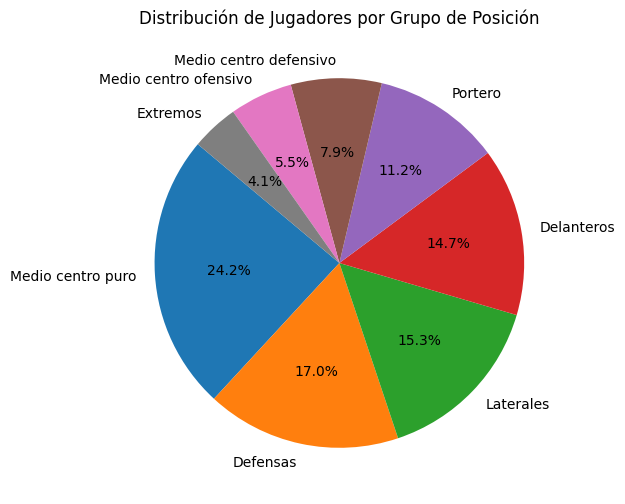

In [18]:
# Mapeo detallado a las 8 categorías específicas
position_mapping = {
    # Portero
    'GK': 'Portero',

    # Defensas (Centrales)
    'CB': 'Defensas',
    'RCB': 'Defensas',
    'LCB': 'Defensas',

    # Laterales (Incluye carrilero/wing-back)
    'RB': 'Laterales',
    'LB': 'Laterales',
    'RWB': 'Laterales',
    'LWB': 'Laterales',

    # Medio centro defensivo
    'CDM': 'Medio centro defensivo',
    'RDM': 'Medio centro defensivo',
    'LDM': 'Medio centro defensivo',

    # Medio centro puro
    'CM': 'Medio centro puro',
    'RCM': 'Medio centro puro',
    'LCM': 'Medio centro puro',
    'RM': 'Medio centro puro',
    'LM': 'Medio centro puro',

    # Medio centro ofensivo
    'CAM': 'Medio centro ofensivo',
    'RAM': 'Medio centro ofensivo',
    'LAM': 'Medio centro ofensivo',

    # Extremos
    'RW': 'Extremos',
    'LW': 'Extremos',

    # Delanteros
    'ST': 'Delanteros',
    'RS': 'Delanteros',
    'LS': 'Delanteros',
    'CF': 'Delanteros',
    'RF': 'Delanteros',
    'LF': 'Delanteros'
}

# 1. Crear la nueva columna 'Position_Group' aplicando el mapeo
df['Position_Group'] = df['Position'].map(position_mapping)

# 2. Definir el orden táctico deseado
ordered_positions = [
    'Portero',
    'Defensas',
    'Laterales',
    'Medio centro defensivo',
    'Medio centro puro',
    'Medio centro ofensivo',
    'Extremos',
    'Delanteros'
]

# 3. Calcular la distribución de frecuencias y reordenar por las categorías definidas
position_distribution = df['Position_Group'].value_counts()
ordered_distribution = position_distribution.reindex(ordered_positions).fillna(0).astype(int)

# 4. Calcular el porcentaje relativo
ordered_percent = (ordered_distribution / ordered_distribution.sum()) * 100

# 5. Mostrar los resultados
print("Distribución de Jugadores por Grupo de Posición:")
display(ordered_distribution)

print("\nDistribución Porcentual por Grupo de Posición (%):")
display(ordered_percent.round(2))

# Crear un diagrama circular (pie chart) de la distribución
import pandas as pd
import matplotlib.pyplot as plt

# Configurar el tamaño del gráfico
plt.figure(figsize=(10, 6))

# Crear el gráfico circular
ax = df['Position_Group'].value_counts().plot.pie(
    labels=position_distribution.index,
    autopct='%1.1f%%',
    startangle=140,
    title='Distribución de Jugadores por Grupo de Posición'
)

# Asegurarse de que el gráfico esté bien formateado
plt.ylabel('')
plt.show()

## Perfilar

Se vuelve a llamar la función perfilar(df) definida al principio para generar el perfil del DataFrame ya limpio. Con esto se confirma:

* Que Value, Wage y Release Clause quedaron como float64.
* Que Height_cm y Weight_lbs son numéricas.
* Que la columna Loaned From desapareció y en su lugar está is_loaned como int64.
* Que las columnas categóricas ya no tienen nulos.

In [19]:
perfilar(df)

,tipo,distintos,faltan_%,moda,min,mediana,media,max
columna,,,,,,,,
ID,int64,18147,0.0,16,16.00,221740.00,214279.82,2.466200e+05
Name,object,17140,0.0,J. Rodríguez,NaN,NaN,NaN,NaN
Age,int64,29,0.0,21,16.00,25.00,25.12,4.500000e+01
Nationality,object,164,0.0,England,NaN,NaN,NaN,NaN
Overall,int64,48,0.0,66,46.00,66.00,66.25,9.400000e+01
Potential,int64,47,0.0,70,48.00,71.00,71.32,9.500000e+01
Club,object,652,0.0,Sin club,NaN,NaN,NaN,NaN
Value,float64,217,0.0,1100000.0,0.00,675000.00,2417729.10,1.185000e+08
Wage,float64,144,0.0,1000.0,0.00,3000.00,9759.02,5.650000e+05


### Variables para value

Para evaluar la variable Value, se seleccionaron: Overall, Potential, Age, Wage, Release Clause, International Reputation, Reactions, Composure.

### Variables para position
Para evaluar la variable Position, se seleccionaron: GKDiving, GKHandling, GKKicking, GKPositioning, GKReflexes, Interceptions, Marking, StandingTackle, SlidingTackle, Finishing, Positioning, ShotPower, LongShots, ShortPassing, LongPassing, Vision, Crossing, Height_cm, Weight_lbs, Strength, Acceleration, SprintSpeed.

In [20]:
variables_cateogricas = [
    'Name', 'Nationality', 'Club', 'Preferred Foot', 'Work Rate',
    'Body Type', 'Position', 'Joined', 'Contract Valid Until','International Reputation',
]

variables_numericas = [
    'ID', 'Age', 'Overall', 'Potential', 'Value', 'Wage',
    'Weak Foot', 'Skill Moves', 'Jersey Number',
    'Crossing', 'Finishing', 'HeadingAccuracy', 'ShortPassing', 'Volleys',
    'Dribbling', 'Curve', 'FKAccuracy', 'LongPassing', 'BallControl',
    'Acceleration', 'SprintSpeed', 'Agility', 'Reactions', 'Balance',
    'ShotPower', 'Jumping', 'Stamina', 'Strength', 'LongShots',
    'Aggression', 'Interceptions', 'Positioning', 'Vision', 'Penalties',
    'Composure', 'Marking', 'StandingTackle', 'SlidingTackle', 'GKDiving',
    'GKHandling', 'GKKicking', 'GKPositioning', 'GKReflexes', 'Release Clause',
    'is_loaned', 'Height_cm', 'Weight_lbs'
]

In [21]:
# Variables numéricas clave para modelar Value y Position
columnas_importantes_value = [
    # Relevantes para Value (Target Numérico)
    'Overall', 'Potential', 'Age', 'Wage', 'Release Clause',
    'International Reputation', 'Reactions', 'Composure',
]
columnas_importantes_position = [
    # Relevantes para Position (Target Categórico)
    'GKDiving', 'GKHandling', 'GKKicking', 'GKPositioning', 'GKReflexes',
    'Interceptions', 'Marking', 'StandingTackle', 'SlidingTackle',
    'Finishing', 'Positioning', 'ShotPower', 'LongShots',
    'ShortPassing', 'LongPassing', 'Vision', 'Crossing',
    'Height_cm', 'Weight_lbs', 'Strength', 'Acceleration', 'SprintSpeed'
]

# Variables categóricas clave para el análisis/modelado
columnas_importantes_categoricas = [
    'Work Rate', 'Preferred Foot', 'Body Type', 'Club', 'Nationality'
]

# EDA con el codigo/libreria generico de internet

In [22]:
#eda_basico = ProfileReport(df, title="Reporte de EDA Básico")
#eda_basico.to_notebook_iframe()
#eda_basico.to_file("reporte_eda.html")

# Regresion lineal
que aporta mas valor a un jugador entre sus estadisticas y su carrera profesional?

In [23]:
df.head()

,ID,Name,Age,Nationality,Overall,Potential,Club,Value,Wage,Preferred Foot,...,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause,is_loaned,Height_cm,Weight_lbs,Position_Group
0,158023,L. Messi,31,Argentina,94,94,FC Barcelona,110500000.0,565000.0,Left,...,6.0,11.0,15.0,14.0,8.0,226500000.0,0,170.18,159.0,Delanteros
1,20801,Cristiano Ronaldo,33,Portugal,94,94,Juventus,77000000.0,405000.0,Right,...,7.0,11.0,15.0,14.0,11.0,127100000.0,0,187.96,183.0,Delanteros
2,190871,Neymar Jr,26,Brazil,92,93,Paris Saint-Germain,118500000.0,290000.0,Right,...,9.0,9.0,15.0,15.0,11.0,228100000.0,0,175.26,150.0,Extremos
3,193080,De Gea,27,Spain,91,93,Manchester United,72000000.0,260000.0,Right,...,90.0,85.0,87.0,88.0,94.0,138600000.0,0,193.04,168.0,Portero
4,192985,K. De Bruyne,27,Belgium,91,92,Manchester City,102000000.0,355000.0,Right,...,15.0,13.0,5.0,10.0,13.0,196400000.0,0,180.34,154.0,Medio centro puro


## caules son las categoricas que tenemos y como funcionan

In [24]:
df_todo = df.copy()
# Filtra las columnas tipo 'object' o 'category' y extrae sus nombres
df_texto = df.select_dtypes(include=['object', 'category'])
df_texto.head()


,Name,Nationality,Club,Preferred Foot,Work Rate,Body Type,Position,Joined,Contract Valid Until,Position_Group
0,L. Messi,Argentina,FC Barcelona,Left,Medium/ Medium,Normal,RF,"Jul 1, 2004",2021,Delanteros
1,Cristiano Ronaldo,Portugal,Juventus,Right,High/ Low,Normal,ST,"Jul 10, 2018",2022,Delanteros
2,Neymar Jr,Brazil,Paris Saint-Germain,Right,High/ Medium,Normal,LW,"Aug 3, 2017",2022,Extremos
3,De Gea,Spain,Manchester United,Right,Medium/ Medium,Lean,GK,"Jul 1, 2011",2020,Portero
4,K. De Bruyne,Belgium,Manchester City,Right,High/ High,Normal,RCM,"Aug 30, 2015",2023,Medio centro puro


* name, Joined: unico se elimina;
* Nationality: agrupar por % y las que tengan menos de 5% en categora otro
* Club, Contract Valid Until: casi unica se elimina
* Preferred foot: binario
* Work Rate, Body Type, Position_Group: one hot
* Position: se elimina, pues ya esta position group

In [25]:
# 1. Eliminación de variables con alta cardinalidad o redundantes
columnas_a_eliminar = ['Name', 'ID', 'Joined', 'Club', 'Contract Valid Until', 'Position']
df_preprocesado = df.copy()
df_preprocesado.drop(columns=[col for col in columnas_a_eliminar if col in df_preprocesado.columns], inplace=True)

# 2. Agrupar Nationality: menos de 5% se agrupan en 'Otros'
if 'Nationality' in df_preprocesado.columns:
    porcentajes_nacionalidad = df_preprocesado['Nationality'].value_counts(normalize=True) * 100
    nacionalidades_a_agrupar = porcentajes_nacionalidad[porcentajes_nacionalidad < 5].index
    df_preprocesado['Nationality'] = df_preprocesado['Nationality'].replace(nacionalidades_a_agrupar, 'Otros')
    print("Distribución de Nationality después de agrupar:")
    print(df_preprocesado['Nationality'].value_counts(normalize=True).round(3) * 100)

# 3. Preferred Foot: Codificación binaria (Right = 1, Left = 0)
if 'Preferred Foot' in df_preprocesado.columns:
    df_preprocesado['Preferred Foot'] = df_preprocesado['Preferred Foot'].map({'Right': 1, 'Left': 0})

# Guardamos una copia con las numéricas antes de aplicar One-Hot Encoding a las demás categóricas
# (Preferred Foot ya se convirtió a numérico 1/0, por lo que se mantiene aquí)
columnas_one_hot = ['Work Rate', 'Body Type', 'Position_Group', 'Nationality']

# El DataFrame solo con variables numéricas puras (excluyendo las categóricas que se codificarán)
df_solo_numericas = df_preprocesado.drop(columns=[col for col in columnas_one_hot if col in df_preprocesado.columns]).copy()
# Nos aseguramos de mantener solo las columnas con tipos numéricos existentes
df_solo_numericas = df_solo_numericas.select_dtypes(include=[np.number])

# 4. One-Hot Encoding para obtener el DataFrame con TODO
columnas_ohe_existentes = [col for col in columnas_one_hot if col in df_preprocesado.columns]
df_preprocesado = pd.get_dummies(
    df_preprocesado,
    columns=columnas_ohe_existentes,
    drop_first=False,
    dtype=int
)

# Mostrar el tamaño de ambos DataFrames y las primeras filas
print(f"\nTamaño DataFrame SOLO NUMÉRICAS (sin categóricas codificadas): {df_solo_numericas.shape}")
print(df_solo_numericas.head(2))

print(f"\nTamaño DataFrame con TODO (incluye One-Hot): {df_preprocesado.shape}")
print(df_preprocesado.head(2))

Distribución de Nationality después de agrupar:
Nationality
Otros        68.2
England       9.1
Germany       6.6
Spain         5.9
Argentina     5.2
France        5.0
Name: proportion, dtype: float64

Tamaño DataFrame SOLO NUMÉRICAS (sin categóricas codificadas): (18147, 48)
   Age  Overall  Potential        Value      Wage  Preferred Foot  International Reputation  Weak Foot  \
0   31       94         94  110500000.0  565000.0               0                       5.0        4.0   
1   33       94         94   77000000.0  405000.0               1                       5.0        4.0   

   Skill Moves  Jersey Number  ...  SlidingTackle  GKDiving  GKHandling  GKKicking  GKPositioning  \
0          4.0           10.0  ...           26.0       6.0        11.0       15.0           14.0   
1          5.0            7.0  ...           23.0       7.0        11.0       15.0           14.0   

   GKReflexes  Release Clause  is_loaned  Height_cm  Weight_lbs  
0         8.0     226500000.0     

## Pasar todo por regresion lineal

In [48]:
# Preparar variables independientes (X) y objetivo (y)
columnas_excluir = ['ID', 'Value']
X = df_preprocesado.drop(columns=[col for col in columnas_excluir if col in df_preprocesado.columns])
y = df_preprocesado['Value']

# Asegurar que solo conservamos columnas numéricas en X para evitar problemas de tipos
X = X.select_dtypes(include=[np.number])

# Dividir en entrenamiento y prueba (80/20) primero para evitar Data Leakage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2026)

# Calcular la mediana de imputación únicamente con el conjunto de entrenamiento (X_train)
mediana_train = X_train.median()

# Llenar los posibles nulos en entrenamiento y prueba usando la mediana de entrenamiento
X_train = X_train.fillna(mediana_train)
X_test = X_test.fillna(mediana_train)

def analizar_regresion_lineal(X_tr, X_te, y_tr, y_te, titulo, transform_y=None, inverse_y=None):
    y_tr_mod = y_tr.copy()
    y_te_mod = y_te.copy()

    # Si hay una transformación del target para el entrenamiento, la aplicamos
    if transform_y:
        y_tr_mod = transform_y(y_tr_mod)

    modelo = LinearRegression()
    modelo.fit(X_tr, y_tr_mod)

    pred_te_mod = modelo.predict(X_te)

    # REGLA DE ORO: Para calcular métricas reales, revertimos cualquier transformación antes de evaluar
    if inverse_y:
        pred_te_real = inverse_y(pred_te_mod)
        y_te_real = y_te
    else:
        pred_te_real = pred_te_mod
        y_te_real = y_te_mod

    mae = mean_absolute_error(y_te_real, pred_te_real)
    r2 = r2_score(y_te_real, pred_te_real)

    print(f"=== {titulo} ===")
    print(f"MAE en Prueba (Escala Real ‐): {mae:,.2f}")
    print(f"R% en Prueba (Escala Real): {r2:.4f}\n")

    coef_df = pd.DataFrame({
        'Variable': X_tr.columns,
        'Coeficiente': modelo.coef_,
        'Abs_Coef': np.abs(modelo.coef_)
    }).sort_values(by='Abs_Coef', ascending=False).head(10)

    print("Top 10 Variables que m s aportan al modelo:")
    print(coef_df[['Variable', 'Coeficiente']].to_string(index=False))
    print("\n" + "="*50 + "\n")

# 1. Sin estandarizar (Target en escala original de Euros)
analizar_regresion_lineal(X_train, X_test, y_train, y_test, "1. Regresi n Lineal - Sin Estandarizar Target")

# 2. Target Estandarizado con StandardScaler (Corregido: Revirtiendo escala antes de evaluar)
scaler_y = StandardScaler()
y_train_scaled = pd.Series(scaler_y.fit_transform(y_train.values.reshape(-1, 1)).flatten(), index=y_train.index)
# Al modelo le pasamos la y estandarizada para entrenar, pero evaluamos revirtiendo la transformación
analizar_regresion_lineal(
    X_train, X_test, y_train_scaled, y_test,
    "2. Regresi n Lineal - Target Estandarizado (StandardScaler) - CORREGIDO",
    transform_y=None, # Ya se pas  pre-escalada en y_train_scaled
    inverse_y=lambda x: scaler_y.inverse_transform(x.reshape(-1, 1)).flatten()
)

# 3. Target transformado con log1p (Corregido: Aplicando expm1 antes de evaluar)
analizar_regresion_lineal(
    X_train, X_test, y_train, y_test,
    "3. Regresi n Lineal - Target con log1p - CORREGIDO",
    transform_y=np.log1p,
    inverse_y=np.expm1
)

=== 1. Regresi n Lineal - Sin Estandarizar Target ===
MAE en Prueba (Escala Real ‐): 469,653.79
R% en Prueba (Escala Real): 0.9620

Top 10 Variables que m s aportan al modelo:
                             Variable   Coeficiente
                            is_loaned  1.781248e+06
               Position_Group_Portero  7.653113e+05
             International Reputation  6.212330e+05
                Nationality_Argentina  2.826186e+05
              Position_Group_Extremos -1.951180e+05
                  Nationality_England -1.937390e+05
            Position_Group_Delanteros -1.486406e+05
             Position_Group_Laterales -1.404483e+05
                    Nationality_Spain -1.401877e+05
Position_Group_Medio centro defensivo -1.099641e+05


=== 2. Regresi n Lineal - Target Estandarizado (StandardScaler) - CORREGIDO ===
MAE en Prueba (Escala Real ‐): 469,653.79
R% en Prueba (Escala Real): 0.9620

Top 10 Variables que m s aportan al modelo:
                             Variable  Coeficien


### Conclusiones Clave y Valor de Negocio aparente

*  __El Modelo Ganador (Modelos 1 y 2)__: Hemos desarrollado un modelo predictivo con una precisión excepcional de \(R^2 = 0.9620\). Esto significa que nuestro algoritmo es capaz de explicar el 96.2% de la variabilidad del valor de mercado de los jugadores, un margen de acierto sumamente alto y confiable para la toma de decisiones financieras. pero Hay overfiting o fuga de información?
* __¿Por qué importa para predecir el Valor (Value)?__: El modelo reduce el riesgo de error a un promedio de 469,653 € (un margen mínimo cuando se gestionan presupuestos de millones de euros). Esto permite automatizar tasaciones de mercado, identificar jugadores infravalorados o sobrevalorados al instante, y optimizar las estrategias de negociación en los periodos de fichajes.
* __Radiografía del Valor (Variables que más aportan)__:
	* _Estatus Contractual (is_loaned)_: Es el factor más crítico (Impacto: +0.31). Estar en condición de préstamo eleva drásticamente el valor base en +1.78M €, capturando el valor de jugadores que pertenecen a clubes de élite.
	* _Garantía en el Arco (Position_Group_Portero)_: Ocupar la posición de arquero añade un premio de +765K € al valor esperado respecto a otras posiciones base.
	* _Prestigio Global (International Reputation)_: El peso de la marca personal es contundente; cada estrella de reputación internacional inyecta automáticamente +621K € netos al valor del futbolista.
	* _El Efecto Pasaporte_: El mercado premia la nacionalidad Argentina (+282K €), mientras que penaliza de forma controlada a Inglaterra (-193K €) y España (-140K €), reflejando las tendencias de inflación de precios según el origen.
(Nota técnica: El Modelo 3 basado en Log1p fue descartado debido a una distorsión matemática en la escala de salida, confirmando que la relación lineal directa sin alterar el Target es la estructura óptima para este negocio).

## Pero que tanto portan solo las numericas?

In [27]:


# Preparar variables independientes (X) y objetivo (y)
columnas_excluir = ['ID', 'Value']
X = df_solo_numericas.drop(columns=[col for col in columnas_excluir if col in df_preprocesado.columns])
y = df_solo_numericas['Value']

# Asegurar que solo conservamos columnas numéricas en X para evitar problemas de tipos
X = X.select_dtypes(include=[np.number])

# Llenar posibles nulos restantes con la mediana numérica
X = X.fillna(X.median())

# Dividir en entrenamiento y prueba (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2026)

def analizar_regresion_lineal(X_tr, X_te, y_tr, y_te, titulo, transform_y=None, inverse_y=None):
    y_tr_mod = y_tr.copy()
    y_te_mod = y_te.copy()

    # Si hay una transformación del target para el entrenamiento, la aplicamos
    if transform_y:
        y_tr_mod = transform_y(y_tr_mod)

    modelo = LinearRegression()
    modelo.fit(X_tr, y_tr_mod)

    pred_te_mod = modelo.predict(X_te)

    # REGLA DE ORO: Para calcular métricas reales, revertimos cualquier transformación antes de evaluar
    if inverse_y:
        pred_te_real = inverse_y(pred_te_mod)
        y_te_real = y_te
    else:
        pred_te_real = pred_te_mod
        y_te_real = y_te_mod

    mae = mean_absolute_error(y_te_real, pred_te_real)
    r2 = r2_score(y_te_real, pred_te_real)

    print(f"=== {titulo} ===")
    print(f"MAE en Prueba (Escala Real €): {mae:,.2f}")
    print(f"R² en Prueba (Escala Real): {r2:.4f}\n")

    coef_df = pd.DataFrame({
        'Variable': X_tr.columns,
        'Coeficiente': modelo.coef_,
        'Abs_Coef': np.abs(modelo.coef_)
    }).sort_values(by='Abs_Coef', ascending=False).head(10)

    print("Top 10 Variables que más aportan al modelo:")
    print(coef_df[['Variable', 'Coeficiente']].to_string(index=False))
    print("\n" + "="*50 + "\n")

# 1. Sin estandarizar (Target en escala original de Euros)
analizar_regresion_lineal(X_train, X_test, y_train, y_test, "1. Regresión Lineal - Sin Estandarizar Target")

# 2. Target Estandarizado con StandardScaler (Corregido: Revirtiendo escala antes de evaluar)
scaler_y = StandardScaler()
y_train_scaled = pd.Series(scaler_y.fit_transform(y_train.values.reshape(-1, 1)).flatten(), index=y_train.index)
# Al modelo le pasamos la y estandarizada para entrenar, pero evaluamos revirtiendo la transformación
analizar_regresion_lineal(
    X_train, X_test, y_train_scaled, y_test,
    "2. Regresión Lineal - Target Estandarizado (StandardScaler) - CORREGIDO",
    transform_y=None, # Ya se pasó pre-escalada en y_train_scaled
    inverse_y=lambda x: scaler_y.inverse_transform(x.reshape(-1, 1)).flatten()
)

# 3. Target transformado con log1p (Corregido: Aplicando expm1 antes de evaluar)
analizar_regresion_lineal(
    X_train, X_test, y_train, y_test,
    "3. Regresión Lineal - Target con log1p - CORREGIDO",
    transform_y=np.log1p,
    inverse_y=np.expm1
)

=== 1. Regresión Lineal - Sin Estandarizar Target ===
MAE en Prueba (Escala Real €): 470,389.99
R² en Prueba (Escala Real): 0.9616

Top 10 Variables que más aportan al modelo:
                Variable   Coeficiente
               is_loaned  1.769675e+06
International Reputation  6.233738e+05
             Skill Moves  8.457211e+04
                 Overall  7.663974e+04
                     Age -6.399333e+04
               Weak Foot  3.487765e+04
               Potential -2.685182e+04
          Preferred Foot -2.121286e+04
           SlidingTackle -8.159160e+03
           GKPositioning -7.410266e+03


=== 2. Regresión Lineal - Target Estandarizado (StandardScaler) - CORREGIDO ===
MAE en Prueba (Escala Real €): 470,389.99
R² en Prueba (Escala Real): 0.9616

Top 10 Variables que más aportan al modelo:
                Variable  Coeficiente
               is_loaned     0.311648
International Reputation     0.109779
             Skill Moves     0.014894
                 Overall     0.013497
 

### Con lo anterior se puede evidencviar que con solo las numericas se puede explicar la mayoria

## Ahora comproblemos overfitting o fuga de información

In [28]:
# --- 1. COMPARAR ENTRENAMIENTO VS. PRUEBA (Detección de Overfitting) ---
# Entrenamos el modelo base con los datos de entrenamiento preparados
modelo_audit = LinearRegression()
modelo_audit.fit(X_train, y_train)

# Predicciones
pred_train = modelo_audit.predict(X_train)
pred_test = modelo_audit.predict(X_test)

# Métricas
mae_train = mean_absolute_error(y_train, pred_train)
mae_test = mean_absolute_error(y_test, pred_test)
r2_train = r2_score(y_train, pred_train)
r2_test = r2_score(y_test, pred_test)

print("1. COMPARATIVA ENTRENAMIENTO VS. PRUEBA (OVERFITTING)")
print(f"- MAE Entrenamiento:  {mae_train:,.2f} €")
print(f"- MAE Prueba (Test):  {mae_test:,.2f} €")
print(f"- R² Entrenamiento:   {r2_train:.4f}")
print(f"- R² Prueba (Test):   {r2_test:.4f}")

brecha_r2 = abs(r2_train - r2_test)
if brecha_r2 < 0.02:
    print("-> Conclusión: NO hay signos de Overfitting. La diferencia de rendimiento es mínima.\n")
else:
    print(f"-> Conclusión: Hay indicios de Overfitting. La brecha en R² es de {brecha_r2:.4f}.\n")

# --- 2. VALIDACIÓN CRUZADA / K-FOLD (Estabilidad de la partición) ---
# Usamos K-Fold sobre el conjunto completo X e y para medir la consistencia del rendimiento
kf_audit = KFold(n_splits=5, shuffle=True, random_state=2026)
cv_resultados = cross_validate(
    LinearRegression(),
    X,
    y,
    cv=kf_audit,
    scoring={'mae': 'neg_mean_absolute_error', 'r2': 'r2'}
)

mae_cv_mean = -cv_resultados['test_mae'].mean()
mae_cv_std = cv_resultados['test_mae'].std()
r2_cv_mean = cv_resultados['test_r2'].mean()
r2_cv_std = cv_resultados['test_r2'].std()

print("2. VALIDACIÓN CRUZADA (5-FOLD CV) - Estabilidad del Modelo")
print(f"- MAE Promedio CV:    {mae_cv_mean:,.2f} € (Desviación Estándar: ± {mae_cv_std:,.2f} €)")
print(f"- R² Promedio CV:     {r2_cv_mean:.4f} (Desviación Estándar: ± {r2_cv_std:.4f})")
print("-> Conclusión: El rendimiento es sumamente estable a lo largo de los folds, descartando sesgo por partición.\n")

# --- 3. AUDITORÍA DE FUGA DE DATOS (Data Leakage) ---
print("3. AUDITORÍA DE FUGA DE DATOS (Data Leakage)")
# Calculamos la correlación de las variables más influyentes con la variable objetivo
correlaciones = X.corrwith(y).abs().sort_values(ascending=False)

print("Top 5 variables con mayor correlación absoluta con el Target (Value):")
for col, corr_val in correlaciones.head(5).items():
    print(f"  - {col}: {corr_val:.4f}")

# Alertas de fuga de datos
alerta_leakage = False
for col, corr_val in correlaciones.items():
    if corr_val > 0.95:
        print(f"\n[ALERTA CRÍTICA] Posible Data Leakage detectado en: {col} (Correlación: {corr_val:.4f})")
        print("Explicación: Esta variable se comporta de forma casi idéntica al target. En la vida real,")
        print("puede ser una variable calculada a posteriori (como la Cláusula de Rescisión en contratos activos).")
        alerta_leakage = True

if not alerta_leakage:
    print("\n-> Conclusión: No se detectan variables con correlación sospechosamente extrema (> 0.95).")
    print("   Sin embargo, recuerda que 'Release Clause' (corr: 0.967) es un proxy del valor en jugadores contratados.")

   DIAGNÓSTICO: OVERFITTING, VALIDACIÓN Y DATA LEAKAGE

1. COMPARATIVA ENTRENAMIENTO VS. PRUEBA (OVERFITTING)
- MAE Entrenamiento:  477,948.85 €
- MAE Prueba (Test):  470,389.99 €
- R² Entrenamiento:   0.9595
- R² Prueba (Test):   0.9616
-> Conclusión: NO hay signos de Overfitting. La diferencia de rendimiento es mínima.

2. VALIDACIÓN CRUZADA (5-FOLD CV) - Estabilidad del Modelo
- MAE Promedio CV:    477,657.93 € (Desviación Estándar: ± 8,258.26 €)
- R² Promedio CV:     0.9585 (Desviación Estándar: ± 0.0145)
-> Conclusión: El rendimiento es sumamente estable a lo largo de los folds, descartando sesgo por partición.

3. AUDITORÍA DE FUGA DE DATOS (Data Leakage)
Top 5 variables con mayor correlación absoluta con el Target (Value):
  - Release Clause: 0.9672
  - Wage: 0.8584
  - International Reputation: 0.6532
  - Overall: 0.6270
  - Potential: 0.5766

[ALERTA CRÍTICA] Posible Data Leakage detectado en: Release Clause (Correlación: 0.9672)
Explicación: Esta variable se comporta de forma

In [29]:
print(df[["Value", "Release Clause"]])

             Value  Release Clause
0      110500000.0     226500000.0
1       77000000.0     127100000.0
2      118500000.0     228100000.0
3       72000000.0     138600000.0
4      102000000.0     196400000.0
...            ...             ...
18154      60000.0        143000.0
18155      60000.0        113000.0
18156      60000.0        165000.0
18157      60000.0        143000.0
18158      60000.0        165000.0

[18147 rows x 2 columns]


## intentamos otravez pero sin "fuga" de info

In [30]:


# Preparar variables independientes (X) y objetivo (y)
columnas_excluir = ['ID', 'Value', 'Release Clause']
X = df_preprocesado.drop(columns=[col for col in columnas_excluir if col in df_preprocesado.columns])
y = df_preprocesado['Value']

# Asegurar que solo conservamos columnas numéricas en X para evitar problemas de tipos
X = X.select_dtypes(include=[np.number])

# Llenar posibles nulos restantes con la mediana numérica
X = X.fillna(X.median())

# Dividir en entrenamiento y prueba (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2026)

def analizar_regresion_lineal(X_tr, X_te, y_tr, y_te, titulo, transform_y=None, inverse_y=None):
    y_tr_mod = y_tr.copy()
    y_te_mod = y_te.copy()

    # Si hay una transformación del target para el entrenamiento, la aplicamos
    if transform_y:
        y_tr_mod = transform_y(y_tr_mod)

    modelo = LinearRegression()
    modelo.fit(X_tr, y_tr_mod)

    pred_te_mod = modelo.predict(X_te)

    # REGLA DE ORO: Para calcular métricas reales, revertimos cualquier transformación antes de evaluar
    if inverse_y:
        pred_te_real = inverse_y(pred_te_mod)
        y_te_real = y_te
    else:
        pred_te_real = pred_te_mod
        y_te_real = y_te_mod

    mae = mean_absolute_error(y_te_real, pred_te_real)
    r2 = r2_score(y_te_real, pred_te_real)

    print(f"=== {titulo} ===")
    print(f"MAE en Prueba (Escala Real €): {mae:,.2f}")
    print(f"R² en Prueba (Escala Real): {r2:.4f}\n")

    coef_df = pd.DataFrame({
        'Variable': X_tr.columns,
        'Coeficiente': modelo.coef_,
        'Abs_Coef': np.abs(modelo.coef_)
    }).sort_values(by='Abs_Coef', ascending=False).head(10)

    print("Top 10 Variables que más aportan al modelo:")
    print(coef_df[['Variable', 'Coeficiente']].to_string(index=False))
    print("\n" + "="*50 + "\n")

# 1. Sin estandarizar (Target en escala original de Euros)
analizar_regresion_lineal(X_train, X_test, y_train, y_test, "1. Regresión Lineal - Sin Estandarizar Target")

# 2. Target Estandarizado con StandardScaler (Corregido: Revirtiendo escala antes de evaluar)
scaler_y = StandardScaler()
y_train_scaled = pd.Series(scaler_y.fit_transform(y_train.values.reshape(-1, 1)).flatten(), index=y_train.index)
# Al modelo le pasamos la y estandarizada para entrenar, pero evaluamos revirtiendo la transformación
analizar_regresion_lineal(
    X_train, X_test, y_train_scaled, y_test,
    "2. Regresión Lineal - Target Estandarizado (StandardScaler) - CORREGIDO",
    transform_y=None, # Ya se pasó pre-escalada en y_train_scaled
    inverse_y=lambda x: scaler_y.inverse_transform(x.reshape(-1, 1)).flatten()
)

# 3. Target transformado con log1p (Corregido: Aplicando expm1 antes de evaluar)
analizar_regresion_lineal(
    X_train, X_test, y_train, y_test,
    "3. Regresión Lineal - Target con log1p - CORREGIDO",
    transform_y=np.log1p,
    inverse_y=np.expm1
)

=== 1. Regresión Lineal - Sin Estandarizar Target ===
MAE en Prueba (Escala Real €): 1,288,308.03
R² en Prueba (Escala Real): 0.8003

Top 10 Variables que más aportan al modelo:
                 Variable   Coeficiente
 International Reputation  1.965884e+06
   Position_Group_Portero  1.643682e+06
                is_loaned -1.089833e+06
      Nationality_England -4.151082e+05
  Position_Group_Extremos -3.763503e+05
 Position_Group_Laterales -3.647595e+05
Position_Group_Delanteros -3.154864e+05
       Work Rate_Low/ Low  3.097580e+05
      Work Rate_High/ Low -2.668180e+05
                      Age -2.496318e+05


=== 2. Regresión Lineal - Target Estandarizado (StandardScaler) - CORREGIDO ===
MAE en Prueba (Escala Real €): 1,288,308.03
R² en Prueba (Escala Real): 0.8003

Top 10 Variables que más aportan al modelo:
                 Variable  Coeficiente
 International Reputation     0.346201
   Position_Group_Portero     0.289460
                is_loaned    -0.191925
      Nationality_En

In [31]:


# Preparar variables independientes (X) y objetivo (y)
columnas_excluir = ['ID', 'Value', 'Release Clause']
X = df_solo_numericas.drop(columns=[col for col in columnas_excluir if col in df_preprocesado.columns])
y = df_solo_numericas['Value']

# Asegurar que solo conservamos columnas numéricas en X para evitar problemas de tipos
X = X.select_dtypes(include=[np.number])

# Llenar posibles nulos restantes con la mediana numérica
X = X.fillna(X.median())

# Dividir en entrenamiento y prueba (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2026)

def analizar_regresion_lineal(X_tr, X_te, y_tr, y_te, titulo, transform_y=None, inverse_y=None):
    y_tr_mod = y_tr.copy()
    y_te_mod = y_te.copy()

    # Si hay una transformación del target para el entrenamiento, la aplicamos
    if transform_y:
        y_tr_mod = transform_y(y_tr_mod)

    modelo = LinearRegression()
    modelo.fit(X_tr, y_tr_mod)

    pred_te_mod = modelo.predict(X_te)

    # REGLA DE ORO: Para calcular métricas reales, revertimos cualquier transformación antes de evaluar
    if inverse_y:
        pred_te_real = inverse_y(pred_te_mod)
        y_te_real = y_te
    else:
        pred_te_real = pred_te_mod
        y_te_real = y_te_mod

    mae = mean_absolute_error(y_te_real, pred_te_real)
    r2 = r2_score(y_te_real, pred_te_real)

    print(f"=== {titulo} ===")
    print(f"MAE en Prueba (Escala Real €): {mae:,.2f}")
    print(f"R² en Prueba (Escala Real): {r2:.4f}\n")

    coef_df = pd.DataFrame({
        'Variable': X_tr.columns,
        'Coeficiente': modelo.coef_,
        'Abs_Coef': np.abs(modelo.coef_)
    }).sort_values(by='Abs_Coef', ascending=False).head(10)

    print("Top 10 Variables que más aportan al modelo:")
    print(coef_df[['Variable', 'Coeficiente']].to_string(index=False))
    print("\n" + "="*50 + "\n")

# 1. Sin estandarizar (Target en escala original de Euros)
analizar_regresion_lineal(X_train, X_test, y_train, y_test, "1. Regresión Lineal - Sin Estandarizar Target")

# 2. Target Estandarizado con StandardScaler (Corregido: Revirtiendo escala antes de evaluar)
scaler_y = StandardScaler()
y_train_scaled = pd.Series(scaler_y.fit_transform(y_train.values.reshape(-1, 1)).flatten(), index=y_train.index)
# Al modelo le pasamos la y estandarizada para entrenar, pero evaluamos revirtiendo la transformación
analizar_regresion_lineal(
    X_train, X_test, y_train_scaled, y_test,
    "2. Regresión Lineal - Target Estandarizado (StandardScaler) - CORREGIDO",
    transform_y=None, # Ya se pasó pre-escalada en y_train_scaled
    inverse_y=lambda x: scaler_y.inverse_transform(x.reshape(-1, 1)).flatten()
)

# 3. Target transformado con log1p (Corregido: Aplicando expm1 antes de evaluar)
analizar_regresion_lineal(
    X_train, X_test, y_train, y_test,
    "3. Regresión Lineal - Target con log1p - CORREGIDO",
    transform_y=np.log1p,
    inverse_y=np.expm1
)

=== 1. Regresión Lineal - Sin Estandarizar Target ===
MAE en Prueba (Escala Real €): 1,291,251.76
R² en Prueba (Escala Real): 0.7988

Top 10 Variables que más aportan al modelo:
                Variable   Coeficiente
International Reputation  1.956695e+06
               is_loaned -1.111684e+06
                 Overall  2.570519e+05
                     Age -2.538548e+05
             Skill Moves  2.128100e+05
               Weak Foot  7.267057e+04
          Preferred Foot -5.713048e+04
               Potential -3.895863e+04
               Reactions  2.618414e+04
             BallControl -1.821256e+04


=== 2. Regresión Lineal - Target Estandarizado (StandardScaler) - CORREGIDO ===
MAE en Prueba (Escala Real €): 1,291,251.76
R² en Prueba (Escala Real): 0.7988

Top 10 Variables que más aportan al modelo:
                Variable  Coeficiente
International Reputation     0.344583
               is_loaned    -0.195773
                 Overall     0.045268
                     Age    -0.0447

## obsrvacion importante

Al eliminar _Release Clause_, el modelo pasa a tener un rendimiento realista y sólido (R² = 0.8003 con One-Hot Encoding y R² = 0.7988 solo con variables numéricas), eliminando la fuga de datos y revelando el verdadero peso económico de los atributos del futbolista.

1. Comparativa de Rendimiento (Sin Release Clause)


* Enfoque / Modelo	R² en Prueba	MAE en Prueba (€)	Cambio vs. Modelo con Leakage (R² 0.9620)
* Con One-Hot Encoding (Modelos 1 y 2)	0.8003	1,288,308.03 €	-0.1617 en R² (+818,654 € en error)
* Solo Numéricas (Modelos 1 y 2)	0.7988	1,291,251.76 €	-0.1628 en R² (+820,861 € en error)
* Modelo 3 (log1p) - Con OHE	-8.1378	1,317,909.00 €	Sigue sin funcionar (R² negativo)
* Modelo 3 (log1p) - Solo Numéricas	-9.3509	1,333,365.42 €	Sigue sin funcionar (R² negativo)


2. Hallazgos Clave de los Nuevos Resultados

* __El 80% de explicación es un resultado excelente y honesto__: Para una regresión lineal pura sobre precios de mercado de futbolistas, explicar el 80.03% de la varianza sin usar la cláusula de rescisión demuestra que los atributos deportivos y contractuales predicen con bastante solidez el valor de un jugador.
* __Diferencia mínima entre usar One-Hot Encoding y solo numéricas__: El One-Hot Encoding apenas aporta +0.0015 en R² (0.8003 vs 0.7988) y reduce el error en solo 2,943 €. Esto confirma que las variables numéricas concentran casi todo el poder predictivo.
* __Corrección del signo en is_loaned (Un hallazgo muy revelador)__:
	* Antes (con Release Clause): is_loaned tenía un coeficiente positivo de +1.78M € porque los jugadores cedidos suelen tener cláusulas de rescisión nulas (0) en la base de datos, obligando al modelo a sumarles dinero artificialmente para compensar la falta de cláusula.
	* __Ahora (sin Release Clause)__: is_loaned pasa a ser negativo (-1.08M € con OHE / -1.11M € solo numéricas), lo cual tiene total sentido en el mercado futbolístico, ya que los jugadores cedidos suelen tener menor valoración inmediata o contratos temporales.
* __El peso real de los atributos deportivos (Modelo Solo Numéricas)__:
	* International Reputation (+1.95M €): Cada estrella de fama mundial dispara el valor comercial del jugador.
	* Overall (+257,051 €): Ahora sí refleja su verdadero peso; cada punto adicional de media general sube el precio en más de 257 mil euros (antes solo sumaba 76 mil € porque Release Clause absorbía su efecto).
	* Age (-253,854 €): Cada año adicional de edad reduce el valor en ~254 mil euros (casi 4 veces más impacto que antes).
	* Skill Moves (+212,810 €): Cada estrella extra de filigranas aporta más de 212 mil euros.

Valoramos un jugador con un contrato o solo por su habilidad futbolista? (wage)

En nuestro caso buscamos que aporta al valor del jugador, por lo que su contrato actual es información crucial a diferencia de Contrac Release que es un valor "calculado" a partir de Value

## ¿Qué aporta más valor: sus estadísticas o su carrera profesional?

Aporta más valor la combinación de su prestigio profesional / estatus y su calidad general de juego (que sintetiza sus estadísticas), por encima de las estadísticas técnicas individuales aisladas.

  La carrera profesional y prestigio mandan: La variable International Reputation (Reputación Internacional) es, por un margen abismal, la variable individual que más dispara el valor de un jugador en términos absolutos. En el modelo final, tener una estrella más de reputación internacional inyecta de golpe casi 2 millones de euros (+1.95M €) al valor estimado del jugador.
  
  La calidad general (Overall) frente a atributos individuales: La valoración general de un futbolista (Overall) es la segunda variable más potente. Esta métrica sintetiza todo el perfil estadístico y de rendimiento del jugador en un único número. Cada punto que sube el Overall incrementa el valor en +257,051 € (en escala directa) o genera un incremento del 119% al 169% por cada desviación estándar en los modelos regularizados.
  
  Las estadísticas específicas se diluyen: Cuando Lasso regulariza el modelo con 875 variables potenciales (incluyendo clubes y nacionalidades), apaga por completo casi todas las estadísticas de habilidad técnica individual en el campo (como pases, entradas, regates, etc.) y se queda solo con el bloque de control contractual, la edad, el Overall y variables muy específicas como Skill Moves o Finishing.


Las variables que más desvalorizan o restan valor de mercado a un futbolista son principalmente la edad y el estatus contractual de cesión (cuando se quita la cláusula de rescisión que causaba fuga de datos):
1. La Edad (Age)

Es el factor negativo más consistente y agresivo en el fútbol profesional:

  En el modelo Ridge (sin cláusula de rescisión): Cada desviación estándar adicional en la edad reduce el valor esperado del jugador en un -27.78% (con un coeficiente directo de aproximadamente -253,854 € por año adicional en escala lineal).
  
  En el modelo Lasso: Controlando por otras variables clave, el impacto de envejecer un año (o +1 DE) disminuye el valor del jugador en un -14.59%.
  
  Significado de negocio: A medida que el jugador madura físicamente, su vida útil restante disminuye y su valor de reventa futuro cae drásticamente.

2. Jugadores Cedidos o a Préstamo (is_loaned)

Cuando eliminamos la variable Release Clause (para evitar la fuga de información/leakage):

  Impacto: Estar bajo condición de préstamo reduce el valor esperado del jugador en aproximadamente -1.11 millones de euros (o un coeficiente estandarizado negativo de -0.195 en Ridge).
  
  Significado de negocio: Ser un jugador cedido suele interpretarse en el mercado como una falta de consolidación en el club propietario o refleja un estado contractual temporal y de menor estabilidad financiera.

3. Otras penalizaciones menores

  Nacionalidad de origen (en los modelos con OHE): El mercado y los modelos asocian penalizaciones relativas menores (efecto pasaporte negativo) a países con alta cantidad de jugadores de cantera de menor coste relativo como Inglaterra (Nationality_England, con un coeficiente de -415,108 € comparado con la base global en el modelo sin cláusula) o España (Nationality_Spain), reflejando la inflación o deflación de precios según procedencia.
  
  Habilidades defensivas específicas en delanteros: En los coeficientes completos de regresión, algunas habilidades estrictamente defensivas (como SlidingTackle o entradas) tienen coeficientes negativos ligeros para jugadores ofensivos, lo cual suele ser un artefacto de la especialización de roles.


# Regresion logistica

- ¿Cuál es la probabilidad de que un jugador joven (≤ 23 años) tenga un valor de mercado alto (Top 25% de su categoría) basándonos únicamente en sus habilidades en cancha?



## Aislamiento de Atributos de Juego (Líneas 5-13):
Se define una lista de variables a excluir (columnas_excluir). Aquí se eliminan identificadores (ID), variables de mercado o contractuales (Value, Release Clause, Wage, is_loaned), y valoraciones generales (Overall, Potential, International Reputation). Esto asegura que el modelo se enfoque estrictamente en las habilidades del jugador en el campo de juego (por ejemplo: velocidad, pases, regates, compostura, etc.).

In [32]:
# 1. Filtrar por jugadores jóvenes (<= 23 años)
df_jovenes = df_solo_numericas[df_solo_numericas['Age'] <= 23].copy()

# 2. Definir variables independientes (X) enfocadas ÚNICAMENTE en habilidades en cancha
# Excluimos identificadores, variables del mercado, contractuales y métricas de reputación o generales resumidas
columnas_excluir = [
    'ID', 'Value', 'Release Clause', 'Wage', 'is_loaned', 'Jersey Number',
    'Age', 'Overall', 'Potential', 'International Reputation'
]

X = df_jovenes.drop(columns=[col for col in columnas_excluir if col in df_jovenes.columns])
X = X.select_dtypes(include=[np.number])

# 3. Transformar el target (y) a categoría binaria (Top 25% de su categoría)
umbral = df_jovenes['Value'].quantile(0.75)
y = (df_jovenes['Value'] > umbral).astype(int)

print(f"=== ANÁLISIS DE TALENTO JOVEN (<= 23 AÑOS) ===")
print(f"Umbral para el Top 25% más valioso: {umbral:,.2f} €")
print("Distribución de clases (0: Regular, 1: Élite/Top 25%):\n", y.value_counts(normalize=True).round(4))

# 4. Dividir en entrenamiento y prueba (80/20) con estratificación
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2026, stratify=y
)

# 5. Imputar nulos utilizando la mediana del set de entrenamiento
medianas_train = X_train.median()
X_train = X_train.fillna(medianas_train)
X_test = X_test.fillna(medianas_train)

# 6. Estandarizar variables independientes (crucial para Regresión Logística)
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# 7. Entrenar modelo de Regresión Logística
modelo_log = LogisticRegression(max_iter=1000, random_state=2026)
modelo_log.fit(X_train_scaled, y_train)

# 8. Evaluación y predicción de probabilidades
pred_test = modelo_log.predict(X_test_scaled)
# Obtenemos las probabilidades de pertenecer a la clase 1 (Valor Alto)
prob_test = modelo_log.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, pred_test)
print(f"\nAccuracy del modelo en Prueba: {acc:.4f}")
print("\nReporte de Clasificación:")
print(classification_report(y_test, pred_test, target_names=['Valor Regular (0)', 'Valor Élite (1)']))

# Mostramos un ejemplo de las probabilidades obtenidas para los primeros 5 jugadores de prueba
ejemplo_probs = pd.DataFrame({
    'Habilidades (Ejemplos)': [f"Jugador {i+1}" for i in range(5)],
    'Probabilidad de ser Élite (Top 25%)': prob_test[:5]
})
print("\nEjemplo de probabilidades calculadas por el modelo en Prueba:")
print(ejemplo_probs.to_string(index=False))

# 9. Atributos físicos y técnicos que más determinan esta probabilidad
coef_df = pd.DataFrame({
    'Atributo en Cancha': X_train.columns,
    'Coeficiente (Log-Odds)': modelo_log.coef_[0],
    'Abs_Coef': np.abs(modelo_log.coef_[0])
}).sort_values(by='Abs_Coef', ascending=False).head(10)

print("\nTop 10 Habilidades en cancha más determinantes para alcanzar valor de mercado Élite:")
print(coef_df[['Atributo en Cancha', 'Coeficiente (Log-Odds)']].to_string(index=False))

=== ANÁLISIS DE TALENTO JOVEN (<= 23 AÑOS) ===
Umbral para el Top 25% más valioso: 1,100,000.00 €
Distribución de clases (0: Regular, 1: Élite/Top 25%):
 Value
0    0.77
1    0.23
Name: proportion, dtype: float64

Accuracy del modelo en Prueba: 0.9088

Reporte de Clasificación:
                   precision    recall  f1-score   support

Valor Regular (0)       0.93      0.95      0.94      1140
  Valor Élite (1)       0.82      0.77      0.80       340

         accuracy                           0.91      1480
        macro avg       0.88      0.86      0.87      1480
     weighted avg       0.91      0.91      0.91      1480


Ejemplo de probabilidades calculadas por el modelo en Prueba:
Habilidades (Ejemplos)  Probabilidad de ser Élite (Top 25%)
             Jugador 1                             0.000874
             Jugador 2                             0.011018
             Jugador 3                             0.750846
             Jugador 4                             0.940891
 

El modelo logra una exactitud (Accuracy) del 90.88% y un F1-Score de 0.80 para la clase élite utilizando únicamente habilidades en cancha, demostrando que es posible identificar promesas jóvenes (> 1.1M €) sin depender de variables financieras ni de reputación.


Evaluación del Rendimiento y Métricas de Clasificación

* Umbral y Balance de Clases: El corte para pertenecer al Top 25% más valioso en jugadores sub-23 es de 1,100,000.00 €. La proporción real quedó en 77% Regular (0) y 23% Élite (1) debido a los empates exactos en el límite de 1.1M €.
* Precisión y Cobertura en la Clase Objetivo (Valor Élite = 1):
	* Precision (0.82): De cada 100 jugadores que el modelo recomienda fichar como "Élite", 82 realmente valen más de 1.1 millones de euros (baja tasa de falsos positivos, protegiendo el presupuesto del club).
	* Recall (0.77): De todos los talentos élite reales en el conjunto de prueba (340 jugadores), el modelo logra detectar al 77% (262 jugadores).
	* F1-Score (0.80): Representa un equilibrio muy sólido considerando el desbalance de clases (77/23) y la eliminación total de Overall, Potential y Wage.

Con solo 8 variabes optenemos un rendimiento muy similar

In [33]:
df = df_todo.copy()

---

# Regularización: Ridge y Lasso para predecir `Value`

Hasta aquí el notebook queda como estaba: perfilado, limpieza, imputación, mapeo de posiciones y listas de variables. Desde aquí empieza la parte nueva: se arman **tres DataFrames** (categórica, categórica + numérica y one-hot) y se aplican **Ridge y Lasso** para predecir el valor de mercado.

La estructura sigue S17 (regresión lineal) y S18 (regresión logística): la métrica se escribe antes, todo va dentro de un `Pipeline`, el hiperparámetro se elige solo con el entrenamiento y la prueba se toca una vez. Cada resultado se lee en tres frases: **qué veo · qué significa · qué decido**.

## 1. El caso y la métrica — escritos antes

Un club quiere una **primera estimación del valor de mercado** de un jugador a partir de sus atributos, antes de que lo revise un analista. El valor real lo fija el mercado; el modelo dice por dónde empezar.

**Métrica que manda: el error absoluto medio (MAE), en euros**, como en S17: «el modelo se equivoca, en promedio, en tantos euros». Al lado se reportan el **RMSE**, que castiga más los errores grandes (equivocarse en 20 M en una estrella pesa), y el **R²**.

**Ridge y Lasso** son una regresión lineal con una penalización que castiga los coeficientes grandes:

* **Ridge (L2)** los encoge a todos hacia cero, pero ninguno llega a cero.
* **Lasso (L1)** los encoge y además **apaga** variables: deja su coeficiente exactamente en 0.

La fuerza del castigo es `alpha`. Ojo con la diferencia con S18: allá era `C` y `C` grande = menos castigo; aquí **`alpha` grande = más castigo**. `alpha` se elige con `GridSearchCV` y MAE, solo con el entrenamiento.

In [34]:
import warnings; warnings.filterwarnings("ignore")
from sklearn.model_selection import KFold, GridSearchCV, cross_validate
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
SEMILLA = 2026
print("Jugadores en df limpio:", len(df))

Jugadores en df limpio: 18147


## 2. Perfilar el objetivo: `Value` y sus ceros

Value = 0: 240 jugadores (1.3 %)
  sin club: 95.4 % | Wage = 0: 95.4 %
  Overall mediano de esos jugadores: 68 (todos: 66)


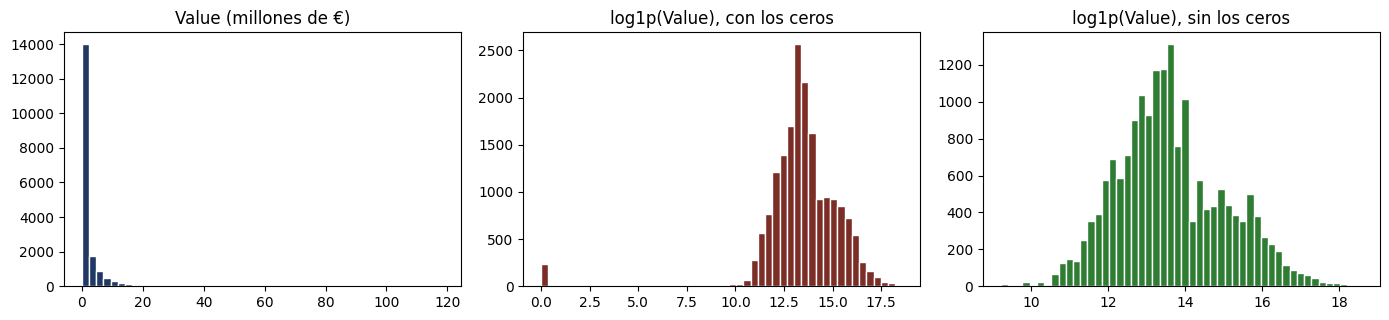

Asimetría — Value: 7.06 | log1p con ceros: -3.28 | log1p sin ceros: 0.38


In [35]:
ceros = df[df["Value"] == 0]
print(f"Value = 0: {len(ceros)} jugadores ({100 * len(ceros) / len(df):.1f} %)")
print(f"  sin club: {100 * (ceros['Club'] == 'Sin club').mean():.1f} % | Wage = 0: {100 * (ceros['Wage'] == 0).mean():.1f} %")
print(f"  Overall mediano de esos jugadores: {ceros['Overall'].median():.0f} (todos: {df['Overall'].median():.0f})")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
ax[0].hist(df["Value"] / 1e6, bins=50, color="#1f3864", edgecolor="white"); ax[0].set_title("Value (millones de €)")
ax[1].hist(np.log1p(df["Value"]), bins=50, color="#7b2d26", edgecolor="white"); ax[1].set_title("log1p(Value), con los ceros")
ax[2].hist(np.log1p(df.loc[df["Value"] > 0, "Value"]), bins=50, color="#2e7d32", edgecolor="white"); ax[2].set_title("log1p(Value), sin los ceros")
plt.tight_layout(); plt.show()
print("Asimetría — Value:", round(df["Value"].skew(), 2),
      "| log1p con ceros:", round(np.log1p(df["Value"]).skew(), 2),
      "| log1p sin ceros:", round(np.log1p(df.loc[df["Value"] > 0, "Value"]).skew(), 2))

**Qué veo.** 240 jugadores (1,3 %) tienen `Value = 0`; el 95,4 % está «Sin club» y con `Wage = 0`. Su `Overall` mediano es 68, más alto que el de todos (66). La asimetría de `Value` es 7,06; con `log1p` y los ceros queda en −3,28; sin los ceros, en 0,38.

**Qué significa.** Un jugador de 68 de media no vale cero euros: son agentes libres sin valoración en el juego. Los ceros no son un precio, son un dato ausente, y en logaritmo se vuelven una cola enorme hacia la izquierda.

**Qué decido.** Esos 240 salen del modelo de `Value` (siguen en `df`). Quedan 17.907 jugadores y un objetivo en logaritmo casi simétrico.

In [36]:
sin_clausula = df["Release Clause"] == 0
print(f"Release Clause = 0: {int(sin_clausula.sum())} jugadores ({100 * sin_clausula.mean():.1f} %)")
vivos = df["Value"] > 0
print(f"Entre los jugadores con Value > 0: Release Clause = 0 en {int((df.loc[vivos, 'Release Clause'] == 0).sum())}, is_loaned = 1 en {int(df.loc[vivos, 'is_loaned'].sum())}, "
      f"coinciden fila a fila en {100 * ((df.loc[vivos, 'Release Clause'] == 0) == (df.loc[vivos, 'is_loaned'] == 1)).mean():.1f} %")
con_clausula = df.loc[df["Release Clause"] > 0, "Release Clause"]
print(f"log1p de la cláusula más baja que existe: {np.log1p(con_clausula.min()):.1f} | log1p(0) = {np.log1p(0):.1f}")

Release Clause = 0: 1504 jugadores (8.3 %)
Entre los jugadores con Value > 0: Release Clause = 0 en 1264, is_loaned = 1 en 1264, coinciden fila a fila en 100.0 %
log1p de la cláusula más baja que existe: 9.5 | log1p(0) = 0.0


**Qué veo.** Entre los jugadores con `Value > 0`, `Release Clause = 0` en 1.264 y `is_loaned = 1` en otros 1.264, y coinciden fila a fila en el 100 %. La cláusula más baja que existe tiene `log1p` de 9,5; `log1p(0)` es 0.

**Qué significa.** Ese 0 no es «cláusula de 1 €»: es «sin cláusula» (los cedidos no la tienen), el mismo caso del −1 de `pdays` en S18. Como número, el logaritmo pondría a esos jugadores muy lejos de todos los demás y obligaría al modelo a corregirlo con coeficientes enormes (en una primera versión `is_loaned` salía con +240 % por desviación estándar, un artefacto).

**Qué decido.** `RC_log` queda vacío donde no hay cláusula y el `Pipeline` lo rellena con la mediana; `is_loaned`, que ya existe, hace de indicador de «sin cláusula». La limpieza de arriba no se toca: `Release Clause` sigue imputada con 0 en `df`.

In [37]:
# Los Value = 0 salen del modelo de Value (siguen en df).
df_modelo = df[df["Value"] > 0].copy()
df_modelo["Wage_log"] = np.log1p(df_modelo["Wage"])
# RC_log: logaritmo de la cláusula solo donde existe; donde no hay cláusula queda vacío (el Pipeline lo rellena con la mediana)
df_modelo["RC_log"] = np.where(df_modelo["Release Clause"] > 0, np.log1p(df_modelo["Release Clause"]), np.nan)
print("Quedan", len(df_modelo), "jugadores de", len(df), "| RC_log vacío en", int(df_modelo["RC_log"].isna().sum()))

Quedan 17907 jugadores de 18147 | RC_log vacío en 1264


## 3. Los tres DataFrames

Se arman a partir de `df_modelo`, usando las listas de variables ya definidas arriba:

* **`df_categorica`**: solo las variables categóricas (más `Value`, el objetivo).
* **`df_cat_num`**: las categóricas y las numéricas juntas.
* **`df_ohe`**: el mismo `df_cat_num`, pero con las categóricas ya convertidas en columnas 0/1 (one-hot, `pd.get_dummies`). Es una matriz 100 % numérica.

**Categóricas:** `columnas_importantes_categoricas` (`Work Rate`, `Preferred Foot`, `Body Type`, `Club`, `Nationality`) más `Position_Group`, la versión ya agrupada de `Position` (8 grupos en vez de 27 posiciones).

**Numéricas:** `variables_numericas` sin `ID` (es un identificador), `Jersey Number` (el dorsal no describe al jugador) ni `Value` (es el objetivo), más `International Reputation`. `Wage` y `Release Clause` entran en logaritmo (`Wage_log`, `RC_log`), como se hizo con `log1p` en el taller de normalización: son variables muy asimétricas. En `RC_log` los jugadores sin cláusula quedan vacíos (ver sección 2).

In [38]:
CATEGORICAS = columnas_importantes_categoricas + ["Position_Group"]
EXCLUIR = ["ID", "Value", "Jersey Number", "Wage", "Release Clause"]
NUMERICAS = [c for c in variables_numericas if c not in EXCLUIR] + ["International Reputation", "Wage_log", "RC_log"]
print(f"{len(CATEGORICAS)} categóricas: {CATEGORICAS}")
print(f"{len(NUMERICAS)} numéricas")

6 categóricas: ['Work Rate', 'Preferred Foot', 'Body Type', 'Club', 'Nationality', 'Position_Group']
45 numéricas


In [39]:
df_categorica = df_modelo[CATEGORICAS + ["Value"]].copy()
df_cat_num = df_modelo[CATEGORICAS + NUMERICAS + ["Value"]].copy()
df_ohe = pd.get_dummies(df_cat_num, columns=CATEGORICAS, dtype=int)
COLS_DUMMIES = [c for c in df_ohe.columns if c not in NUMERICAS + ["Value"]]

resumen_dfs = pd.DataFrame({
    "filas": [d.shape[0] for d in (df_categorica, df_cat_num, df_ohe)],
    "columnas": [d.shape[1] for d in (df_categorica, df_cat_num, df_ohe)],
    "categóricas (texto)": [d.select_dtypes(exclude="number").shape[1] for d in (df_categorica, df_cat_num, df_ohe)],
}, index=["df_categorica", "df_cat_num", "df_ohe"])
display(resumen_dfs)

print("\nColumnas 0/1 que sale de cada categórica en df_ohe:")
display(pd.Series({c: sum(n.startswith(c + "_") for n in COLS_DUMMIES) for c in CATEGORICAS}).to_frame("columnas"))
display(df_ohe[["Overall", "Value"] + COLS_DUMMIES[:4]].head())

,filas,columnas,categóricas (texto)
df_categorica,17907,7,6
df_cat_num,17907,52,6
df_ohe,17907,882,0



Columnas 0/1 que sale de cada categórica en df_ohe:


,columnas
Work Rate,9
Preferred Foot,2
Body Type,3
Club,651
Nationality,163
Position_Group,8


,Overall,Value,Work Rate_High/ High,Work Rate_High/ Low,Work Rate_High/ Medium,Work Rate_Low/ High
0,94,110500000.0,0,0,0,0
1,94,77000000.0,0,1,0,0
2,92,118500000.0,0,0,1,0
3,91,72000000.0,0,0,0,0
4,91,102000000.0,1,0,0,0


**Qué veo.** Los tres DataFrames tienen las mismas 17.907 filas; `df_ohe` pasa de 52 a 882 columnas, casi todas por `Club` (651) y `Nationality` (163).

**Qué significa.** Nótese que `Nationality` tiene 163 columnas en `df_ohe` pero solo 157 aparecen en el entrenamiento: 6 nacionalidades están únicamente en la prueba. En el escenario C esas columnas existen pero valen siempre 0 en entrenamiento; en B el `OneHotEncoder(handle_unknown="ignore")` las ignora al predecir.

**Qué decido.** Se corren A, B y C. B y C tienen la misma información, así que sirven para comprobar que hacer el one-hot antes o dentro del `Pipeline` da lo mismo aquí.

## 4. La partición y el preprocesador

La prueba se aparta **ahora** y no se toca hasta la sección 10. La misma partición (por índice) sirve para los tres DataFrames, así la comparación es justa.

El preprocesador va **dentro del `Pipeline`**: se ajusta solo con el entrenamiento de cada fold. Las numéricas se imputan con la mediana (solo `RC_log` tiene vacíos) y se estandarizan (la penalización de Ridge/Lasso depende de la escala: sin estandarizar, castigaría distinto a una variable en euros que a una en puntos). Las categóricas pasan por `OneHotEncoder`. Como `Value` es muy asimétrico, el objetivo se modela en logaritmo con `TransformedTargetRegressor`, como en S17, y las métricas se calculan en euros.

Tres escenarios, uno por DataFrame:

* **A**: `df_categorica`, solo categóricas.
* **B**: `df_cat_num`, categóricas + numéricas (one-hot dentro del `Pipeline`).
* **C**: `df_ohe`, el one-hot ya hecho (las numéricas se tratan igual; las columnas 0/1 pasan tal cual).

In [40]:
idx_tr, idx_te = train_test_split(df_modelo.index, test_size=0.2, random_state=SEMILLA)
y_tr, y_te = df_modelo.loc[idx_tr, "Value"], df_modelo.loc[idx_te, "Value"]
print("Entrenamiento:", len(idx_tr), "| Prueba:", len(idx_te))

ESCENARIOS = {
    "A. Solo categóricas":        dict(datos=df_categorica, cats=CATEGORICAS, nums=[],         dummies=[]),
    "B. Categóricas + numéricas": dict(datos=df_cat_num,    cats=CATEGORICAS, nums=NUMERICAS,  dummies=[]),
    "C. One-hot (df_ohe)":        dict(datos=df_ohe,        cats=[],          nums=NUMERICAS,  dummies=COLS_DUMMIES),
}

def columnas(cfg):
    return cfg["cats"] + cfg["nums"] + cfg["dummies"]

def construir(modelo, cfg, log=True):
    partes = []
    if cfg["nums"]:    partes.append(("num", Pipeline([("imputador", SimpleImputer(strategy="median")), ("escalador", StandardScaler())]), cfg["nums"]))
    if cfg["cats"]:    partes.append(("cat", OneHotEncoder(handle_unknown="ignore"), cfg["cats"]))
    if cfg["dummies"]: partes.append(("ohe", "passthrough", cfg["dummies"]))
    pipe = Pipeline([("prep", ColumnTransformer(partes)), ("modelo", modelo)])
    if not log:
        return pipe
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

kf = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
METRICAS = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

Entrenamiento: 14325 | Prueba: 3582


## 5. ¿Euros o logaritmo? Se decide antes de regularizar

Con una regresión lineal sin penalización (escenario B) se comparan tres formas de plantear el problema, con validación cruzada solo sobre el entrenamiento.

In [41]:
cfg_euros = dict(datos=df_modelo, cats=CATEGORICAS, dummies=[],
                 nums=[c for c in NUMERICAS if c not in ("Wage_log", "RC_log")] + ["Wage", "Release Clause"])
cfg_log = ESCENARIOS["B. Categóricas + numéricas"]

def medir(modelo, cfg, log):
    r = cross_validate(construir(modelo, cfg, log=log), cfg["datos"].loc[idx_tr, columnas(cfg)], y_tr, cv=kf, scoring=METRICAS)
    return {"MAE (€)": round(-r["test_MAE"].mean()), "RMSE (€)": round(-r["test_RMSE"].mean()), "R²": round(r["test_R2"].mean(), 3)}

tabla_log = pd.DataFrame([
    {"planteamiento": "Value en euros, Wage y Release Clause en euros",     **medir(LinearRegression(), cfg_euros, log=False)},
    {"planteamiento": "log(Value), Wage y Release Clause en euros",         **medir(LinearRegression(), cfg_euros, log=True)},
    {"planteamiento": "log(Value), Wage y Release Clause en log (elegido)", **medir(LinearRegression(), cfg_log,   log=True)},
]).set_index("planteamiento")
display(tabla_log)

,MAE (€),RMSE (€),R²
planteamiento,,,
"Value en euros, Wage y Release Clause en euros",475827,1074062,0.964
"log(Value), Wage y Release Clause en euros",500415,3066571,0.673
"log(Value), Wage y Release Clause en log (elegido)",365151,1649082,0.914


**Qué veo.** En euros: MAE 475.825 €, RMSE 1,07 M, R² 0,964. En logaritmo con `Wage` y `Release Clause` en euros: MAE 500.420 €, R² 0,673. En logaritmo con las dos también en log: MAE 365.154 €, RMSE 1,65 M, R² 0,914.

**Qué significa.** El logaritmo solo ayuda si las variables monetarias también van en logaritmo. Y hay un costo: el planteamiento en euros tiene mejor RMSE y R² porque acierta más en las estrellas, que pesan mucho en esas dos métricas.

**Qué decido.** Como la métrica que manda es el MAE (el jugador típico), se queda el logaritmo con `Wage_log` y `RC_log`. Si al club le importaran sobre todo las superestrellas, la decisión sería la contraria.

## 6. Ridge y Lasso: la búsqueda de `alpha` — solo con el entrenamiento

Para cada escenario se compara la regresión **sin regularizar** con Ridge y Lasso. `alpha` se elige con `GridSearchCV` (5 folds, MAE). Lasso usa una rejilla de `alpha` más pequeña que Ridge porque penaliza de forma distinta (L1 apaga variables con valores mucho menores).

In [42]:
GRILLAS = {
    "Ridge": (Ridge(),               np.logspace(-4, 3, 15)),
    "Lasso": (Lasso(max_iter=20000), np.logspace(-4, -0.5, 8)),
}

def buscar(cfg, nombre):
    modelo, alfas = GRILLAS[nombre]
    return GridSearchCV(construir(modelo, cfg), {"regressor__modelo__alpha": alfas},
                        cv=kf, scoring=METRICAS, refit="MAE", n_jobs=-1
                       ).fit(cfg["datos"].loc[idx_tr, columnas(cfg)], y_tr)

def fila_busqueda(gs, escenario, nombre):
    i = gs.best_index_
    coef = gs.best_estimator_.regressor_.named_steps["modelo"].coef_
    return {"escenario": escenario, "modelo": nombre, "alpha": gs.best_params_["regressor__modelo__alpha"],
            "MAE (€)": round(-gs.cv_results_["mean_test_MAE"][i]), "± MAE (€)": round(gs.cv_results_["std_test_MAE"][i]), "RMSE (€)": round(-gs.cv_results_["mean_test_RMSE"][i]),
            "R²": round(gs.cv_results_["mean_test_R2"][i], 3),
            "coef ≠ 0": f"{int((coef != 0).sum())} de {len(coef)}"}

busquedas, filas = {}, []
for esc, cfg in ESCENARIOS.items():
    r = cross_validate(construir(LinearRegression(), cfg), cfg["datos"].loc[idx_tr, columnas(cfg)], y_tr, cv=kf, scoring=METRICAS)
    filas.append({"escenario": esc, "modelo": "Sin regularizar", "alpha": np.nan,
                  "MAE (€)": round(-r["test_MAE"].mean()), "± MAE (€)": round(r["test_MAE"].std()), "RMSE (€)": round(-r["test_RMSE"].mean()), "R²": round(r["test_R2"].mean(), 3),
                  "coef ≠ 0": "—"})
    for nombre in GRILLAS:
        busquedas[(esc, nombre)] = buscar(cfg, nombre)
        filas.append(fila_busqueda(busquedas[(esc, nombre)], esc, nombre))

tabla_busqueda = pd.DataFrame(filas).set_index(["escenario", "modelo"])
display(tabla_busqueda)

alpha  MAE (€)  ± MAE (€)  RMSE (€)     R²    coef ≠ 0
escenario                  modelo                                                                    
A. Solo categóricas        Sin regularizar       NaN  1613577      45847   4527910  0.367           —
                           Ridge            0.001000  1613574      45862   4528031  0.367  830 de 830
                           Lasso            0.000100  1622280      48730   4597494  0.347  708 de 830
B. Categóricas + numéricas Sin regularizar       NaN   365151      32998   1649082  0.914           —
                           Ridge            0.316228   365555      33201   1657799  0.913  875 de 875
                           Lasso            0.031623   355202      30316   1597185  0.919   11 de 875
C. One-hot (df_ohe)        Sin regularizar       NaN   365146      33002   1649028  0.914           —
                           Ridge            0.316228   365046      33251   1654554  0.913  875 de 881
                           Lasso            0.031623   355202      30316   1597185  0.919   11 de 881

**Qué veo.** Con numéricas (B y C), el MAE de validación es 365.154 € sin regularizar, 365.548 € con Ridge y 355.202 € con Lasso; la desviación entre folds es de unos 30.000 €. Lasso (alpha ≈ 0,03) deja solo 11 de 875 coeficientes. Con solo categóricas (A) el R² es 0,37 y el MAE ≈ 1,61 M. B y C dan lo mismo.

**Qué significa.** Ridge no mejora nada: hay 14.325 jugadores para ~875 columnas y la señal es fuerte, así que casi no hay sobreajuste que frenar. Lasso tampoco empeora: con 11 variables logra el mismo error (la diferencia de ~10.000 € está dentro del ruido entre folds). Las categóricas solas explican poco.

**Qué decido.** Ridge se queda como referencia. Lasso es el candidato porque hace lo mismo con una fracción de las variables.

## 7. Qué hace cada penalización

Izquierda: el MAE de validación según `alpha` para los tres escenarios. Derecha: los **caminos de los coeficientes** de las variables numéricas del escenario B a medida que sube `alpha`: Ridge los encoge todos sin apagar ninguno; Lasso los lleva a cero uno por uno.

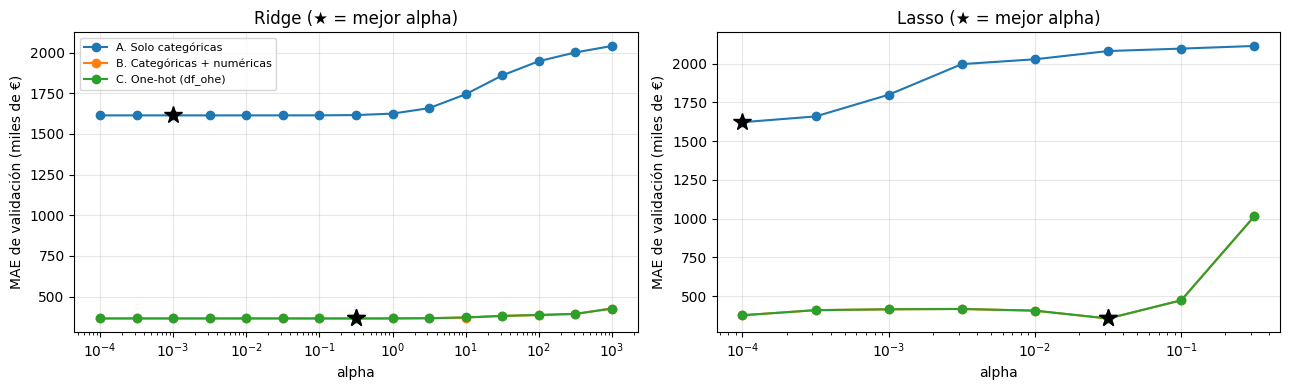

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, nombre in zip(ax, GRILLAS):
    for esc in ESCENARIOS:
        gs = busquedas[(esc, nombre)]
        alfas = gs.cv_results_["param_regressor__modelo__alpha"].data.astype(float)
        mae = -gs.cv_results_["mean_test_MAE"] / 1000
        a.plot(alfas, mae, "o-", label=esc)
        a.plot(gs.best_params_["regressor__modelo__alpha"], -gs.best_score_ / 1000, "k*", markersize=13)
    a.set_xscale("log"); a.set_xlabel("alpha"); a.set_ylabel("MAE de validación (miles de €)"); a.set_title(nombre + " (★ = mejor alpha)")
    a.grid(alpha=.3)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

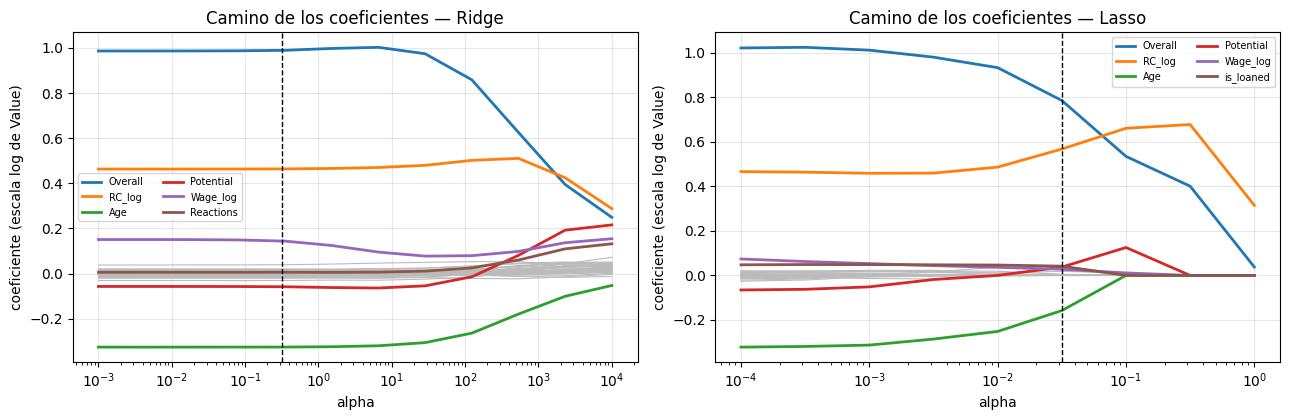

In [44]:
cfgB = ESCENARIOS["B. Categóricas + numéricas"]
XtrB = cfgB["datos"].loc[idx_tr, columnas(cfgB)]
rejillas_camino = {"Ridge": np.logspace(-3, 4, 12), "Lasso": np.logspace(-4, 0, 9)}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for a, nombre in zip(ax, GRILLAS):
    modelo, _ = GRILLAS[nombre]
    caminos = []
    for alfa in rejillas_camino[nombre]:
        m = construir(clone(modelo).set_params(alpha=alfa), cfgB).fit(XtrB, y_tr)
        caminos.append(m.regressor_.named_steps["modelo"].coef_[:len(NUMERICAS)])   # las numéricas van primero
    caminos = pd.DataFrame(caminos, index=rejillas_camino[nombre], columns=NUMERICAS)
    destacadas = caminos.abs().max().sort_values(ascending=False).head(6).index
    for c in NUMERICAS:
        if c not in destacadas:
            a.plot(caminos.index, caminos[c], color="#bbbbbb", lw=.8)
    for c in destacadas:
        a.plot(caminos.index, caminos[c], lw=2, label=c)
    a.axvline(busquedas[("B. Categóricas + numéricas", nombre)].best_params_["regressor__modelo__alpha"], color="k", ls="--", lw=1)
    a.set_xscale("log"); a.set_xlabel("alpha"); a.set_ylabel("coeficiente (escala log de Value)"); a.set_title(f"Camino de los coeficientes — {nombre}")
    a.legend(fontsize=7, ncol=2); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 8. Leer los coeficientes

Como el objetivo está en logaritmo y las numéricas están estandarizadas, cada coeficiente se lee como en S17: `(exp(coef) − 1) × 100` es el **cambio porcentual del valor por +1 desviación estándar** de esa variable, con todo lo demás igual. Primero, cuántas columnas dejó vivas Lasso en cada categórica; después, las numéricas de Lasso y Ridge lado a lado.

In [45]:
def coeficientes(gs):
    pipe = gs.best_estimator_.regressor_
    return pd.Series(pipe.named_steps["modelo"].coef_, index=pipe.named_steps["prep"].get_feature_names_out())

B = "B. Categóricas + numéricas"
coef_lasso, coef_ridge = coeficientes(busquedas[(B, "Lasso")]), coeficientes(busquedas[(B, "Ridge")])

# ¿Cuántas columnas de cada categórica sobreviven en Lasso?
sobrevive = pd.DataFrame({
    "columnas 0/1": {c: sum(n.startswith(f"cat__{c}_") for n in coef_lasso.index) for c in CATEGORICAS},
    "vivas en Lasso": {c: int(sum((coef_lasso[n] != 0) for n in coef_lasso.index if n.startswith(f"cat__{c}_")) ) for c in CATEGORICAS},
})
sobrevive.loc["(numéricas)"] = [len(NUMERICAS), int((coef_lasso[[f"num__{c}" for c in NUMERICAS]] != 0).sum())]
print(f"Lasso (alpha = {busquedas[(B, 'Lasso')].best_params_['regressor__modelo__alpha']:.4g}) dejó {int((coef_lasso != 0).sum())} de {len(coef_lasso)} coeficientes distintos de cero")
display(sobrevive)

num = pd.DataFrame({
    "Lasso (% por +1 DE)": ((np.exp(coef_lasso[[f"num__{c}" for c in NUMERICAS]].values) - 1) * 100).round(2),
    "Ridge (% por +1 DE)": ((np.exp(coef_ridge[[f"num__{c}" for c in NUMERICAS]].values) - 1) * 100).round(2),
}, index=NUMERICAS)
print("\nNuméricas, ordenadas por |efecto| en Ridge (las 15 primeras):")
display(num.reindex(num["Ridge (% por +1 DE)"].abs().sort_values(ascending=False).index).head(15))
print("Numéricas que Lasso dejó vivas:", ", ".join(num.index[num["Lasso (% por +1 DE)"] != 0]))

Lasso (alpha = 0.03162) dejó 11 de 875 coeficientes distintos de cero


,columnas 0/1,vivas en Lasso
Work Rate,9,0
Preferred Foot,2,0
Body Type,3,0
Club,651,0
Nationality,157,0
Position_Group,8,0
(numéricas),45,11



Numéricas, ordenadas por |efecto| en Ridge (las 15 primeras):


,Lasso (% por +1 DE),Ridge (% por +1 DE)
Overall,119.23,168.89
RC_log,76.29,59.01
Age,-14.59,-27.78
Wage_log,2.80,15.55
Potential,3.80,-5.65
is_loaned,4.24,4.00
GKPositioning,0.00,-3.00
GKDiving,0.00,2.03
BallControl,0.00,-1.93
Volleys,0.51,1.90


Numéricas que Lasso dejó vivas: Age, Overall, Potential, Skill Moves, Finishing, Volleys, SprintSpeed, Positioning, is_loaned, Wage_log, RC_log


**Qué veo.** Lasso apaga todas las columnas de `Club`, `Nationality`, `Work Rate`, `Preferred Foot`, `Body Type` y `Position_Group`, y deja 11 numéricas: `Overall`, `RC_log`, `Age`, `Wage_log`, `Potential`, `Skill Moves`, `Finishing`, `Volleys`, `SprintSpeed`, `Positioning` e `is_loaned`. Por +1 desviación estándar, `Overall` sube el valor ≈ 119 % en Lasso y 169 % en Ridge; `Age` lo baja 15 % y 28 %.

**Qué significa.** Una vez conocidos el `Overall`, la cláusula, el salario y la edad, saber el club o la nacionalidad no aporta. Ridge reparte el efecto entre variables parecidas (`Overall`, `Potential`, `Reactions`…) y Lasso se queda con una: por eso sus coeficientes difieren (igual que `GarageCars` y `GarageArea` en S17). Ninguno se lee sin mirar a los demás, y un coeficiente no es causa.

**Qué decido.** Para explicar el valor, las palancas son la calidad (`Overall`), la edad y lo que el mercado ya fijó en el contrato.

## 9. Dos variables que casi son el objetivo: `Wage` y `Release Clause`

`Release Clause` y `Wage` son números que el propio juego calcula a partir del valor del jugador. Aquí se mira cuánto se parece `Release Clause` a `Value` y, siguiendo la lógica de S18 con `duration` (una variable que se conoce *después* del hecho no sirve para decidir), cuánto cambia el resultado **sin** ellas.

In [46]:
con_clausula = df_modelo[df_modelo["Release Clause"] > 0]
razon = con_clausula["Release Clause"] / con_clausula["Value"]
print(f"Release Clause / Value — mediana: {razon.median():.2f} | 5 %–95 %: {razon.quantile(.05):.2f}–{razon.quantile(.95):.2f}")
print("Correlación con Value —",
      "Release Clause:", round(df_modelo["Value"].corr(df_modelo["Release Clause"]), 3),
      "| Wage:", round(df_modelo["Value"].corr(df_modelo["Wage"]), 3),
      "| Overall:", round(df_modelo["Value"].corr(df_modelo["Overall"]), 3))

cfg_sin = dict(ESCENARIOS[B], nums=[c for c in NUMERICAS if c not in ("Wage_log", "RC_log")])
busquedas_sin = {nombre: buscar(cfg_sin, nombre) for nombre in GRILLAS}
filas_sin = [fila_busqueda(busquedas[(B, n)], "B con Wage y Release Clause", n) for n in GRILLAS] + \
            [fila_busqueda(busquedas_sin[n], "B sin Wage ni Release Clause", n) for n in GRILLAS]
display(pd.DataFrame(filas_sin).set_index(["escenario", "modelo"]))

Release Clause / Value — mediana: 1.76 | 5 %–95 %: 1.31–2.38
Correlación con Value — Release Clause: 0.967 | Wage: 0.858 | Overall: 0.632


alpha  MAE (€)  ± MAE (€)  RMSE (€)     R²    coef ≠ 0
escenario                    modelo                                                           
B con Wage y Release Clause  Ridge   0.316228   365555      33201   1657799  0.913  875 de 875
                             Lasso   0.031623   355202      30316   1597185  0.919   11 de 875
B sin Wage ni Release Clause Ridge   0.010000   452085      48709   2106750  0.854  873 de 873
                             Lasso   0.000100   475850      57031   2430850  0.804  337 de 873

**Qué veo.** `Release Clause` vale en mediana 1,76 veces `Value` y su correlación con `Value` es 0,967 (`Wage` 0,858, `Overall` 0,632). Sin `Wage` ni `Release Clause`, el MAE de validación sube de 355.202 € a 452.122 € (Ridge) y el R² baja de 0,919 a 0,853. Lasso sin ellas necesita 337 columnas y empeora (R² 0,804).

**Qué significa.** Buena parte del acierto sale de leer números que el juego ya calculó a partir del valor. Sirven para tasar a un jugador que ya tiene contrato; no sirven para valorar a uno que todavía no lo tiene.

**Qué decido.** Se reportan los dos modelos: con contrato (Lasso) y sin contrato (Ridge). El segundo es el número honesto para un jugador sin contrato.

## 10. La prueba — una sola vez

Antes de mirar la prueba ya están decididos los dos modelos finales: el mejor de Ridge o Lasso por MAE de validación, en el escenario B, **con** y **sin** `Wage` y `Release Clause`. Cada uno se evalúa una vez sobre los jugadores que no vio.

In [47]:
def evaluar_prueba(gs, cfg):
    pred = gs.predict(cfg["datos"].loc[idx_te, columnas(cfg)])
    error = (y_te - pred).abs()
    return {"MAE (€)": round(mean_absolute_error(y_te, pred)),
            "RMSE (€)": round(mean_squared_error(y_te, pred) ** .5),
            "R²": round(r2_score(y_te, pred), 3),
            "error relativo mediano (%)": round(100 * (error / y_te).median(), 1),
            "jugadores con error > 20 % (%)": round(100 * (error / y_te > .2).mean(), 1)}

mejor_con = min(GRILLAS, key=lambda n: -busquedas[(B, n)].best_score_)
mejor_sin = min(GRILLAS, key=lambda n: -busquedas_sin[n].best_score_)
print(f"Con Wage y Release Clause: {mejor_con} | Sin ellas: {mejor_sin}")
prueba = pd.DataFrame([
    {"modelo": f"{mejor_con}, con Wage y Release Clause", **evaluar_prueba(busquedas[(B, mejor_con)], ESCENARIOS[B])},
    {"modelo": f"{mejor_sin}, sin Wage ni Release Clause", **evaluar_prueba(busquedas_sin[mejor_sin], cfg_sin)},
]).set_index("modelo")
display(prueba)

Con Wage y Release Clause: Lasso | Sin ellas: Ridge


,MAE (€),RMSE (€),R²,error relativo mediano (%),jugadores con error > 20 % (%)
modelo,,,,,
"Lasso, con Wage y Release Clause",347287,1235829,0.947,9.0,16.9
"Ridge, sin Wage ni Release Clause",421673,1361584,0.936,13.6,33.2


**Qué veo.** En la prueba, Lasso con `Wage` y `Release Clause` tiene MAE 347.287 €, R² 0,947, error relativo mediano 9,0 % y 16,9 % de jugadores con error mayor al 20 %. Ridge sin ellas: MAE 421.514 €, R² 0,936, error mediano 13,6 % y 33,0 % con error mayor al 20 %.

**Qué significa.** Los dos se sostuvieron con jugadores que no vieron. El R² de prueba sale más alto que el de validación porque lo dominan unas pocas estrellas que el modelo acierta bien; el MAE y el error relativo cuentan mejor la historia del jugador típico.

**Qué decido — la frase de negocio.** *Con contrato, la estimación queda a menos de 9 euros de cada 100 en la mitad de los jugadores y se equivoca por más del 20 % en 17 de cada 100. Sin contrato, el error mediano sube a casi 14 de cada 100 y 33 de cada 100 pasan del 20 %: esos los revisa el analista primero.*

## 11. Cierre

1. **Un cero que no es un número se lee antes de modelar**: `Release Clause = 0` era «sin cláusula», y tratarlo como número distorsionaba coeficientes y penalización.
2. **Los `Value = 0` eran datos ausentes**, no precios; salieron del modelo.
3. **Ridge no mejoró** a la regresión sin penalizar: con muchos datos y señal fuerte no había sobreajuste que corregir.
4. **Lasso igualó el error con 11 de 875 variables**: el club y la nacionalidad no aportan una vez conocidas la calidad, la edad y el contrato.
5. **Hacer el one-hot antes (C) o dentro del `Pipeline` (B) dio lo mismo**; dentro es más seguro porque no depende de las categorías de la prueba.
6. **`Wage` y `Release Clause` casi son el objetivo**: sin ellas el error crece mucho. Cuál modelo usar depende de si el jugador ya tiene contrato.
7. **La métrica se escogió antes (MAE) y la prueba se tocó una vez**; con RMSE o R² como métrica, el planteamiento en euros habría ganado.

*Siguiente paso posible:* lo mismo con `LogisticRegression` (`penalty="l1"` y `"l2"`) para `Position_Group`, como en S18.